# Creating and Backtesting MACD Strategies

## Getting the Data

In [71]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
plt.style.use("ggplot")
%config InlineBackend.figure_format = "retina"

In [72]:
import warnings
warnings.filterwarnings(action = "ignore")

In [73]:
data = pd.read_csv("eurusd.csv", parse_dates = ["Date"], index_col = "Date")

In [74]:
data

,price
Date,
2004-01-01,1.258194
2004-01-02,1.258194
2004-01-05,1.268698
2004-01-06,1.272103
2004-01-07,1.264095
...,...
2020-06-24,1.131235
2020-06-25,1.125087
2020-06-26,1.122208


In [75]:
data.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 4275 entries, 2004-01-01 to 2020-06-30
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   price   4275 non-null   float64
dtypes: float64(1)
memory usage: 66.8 KB


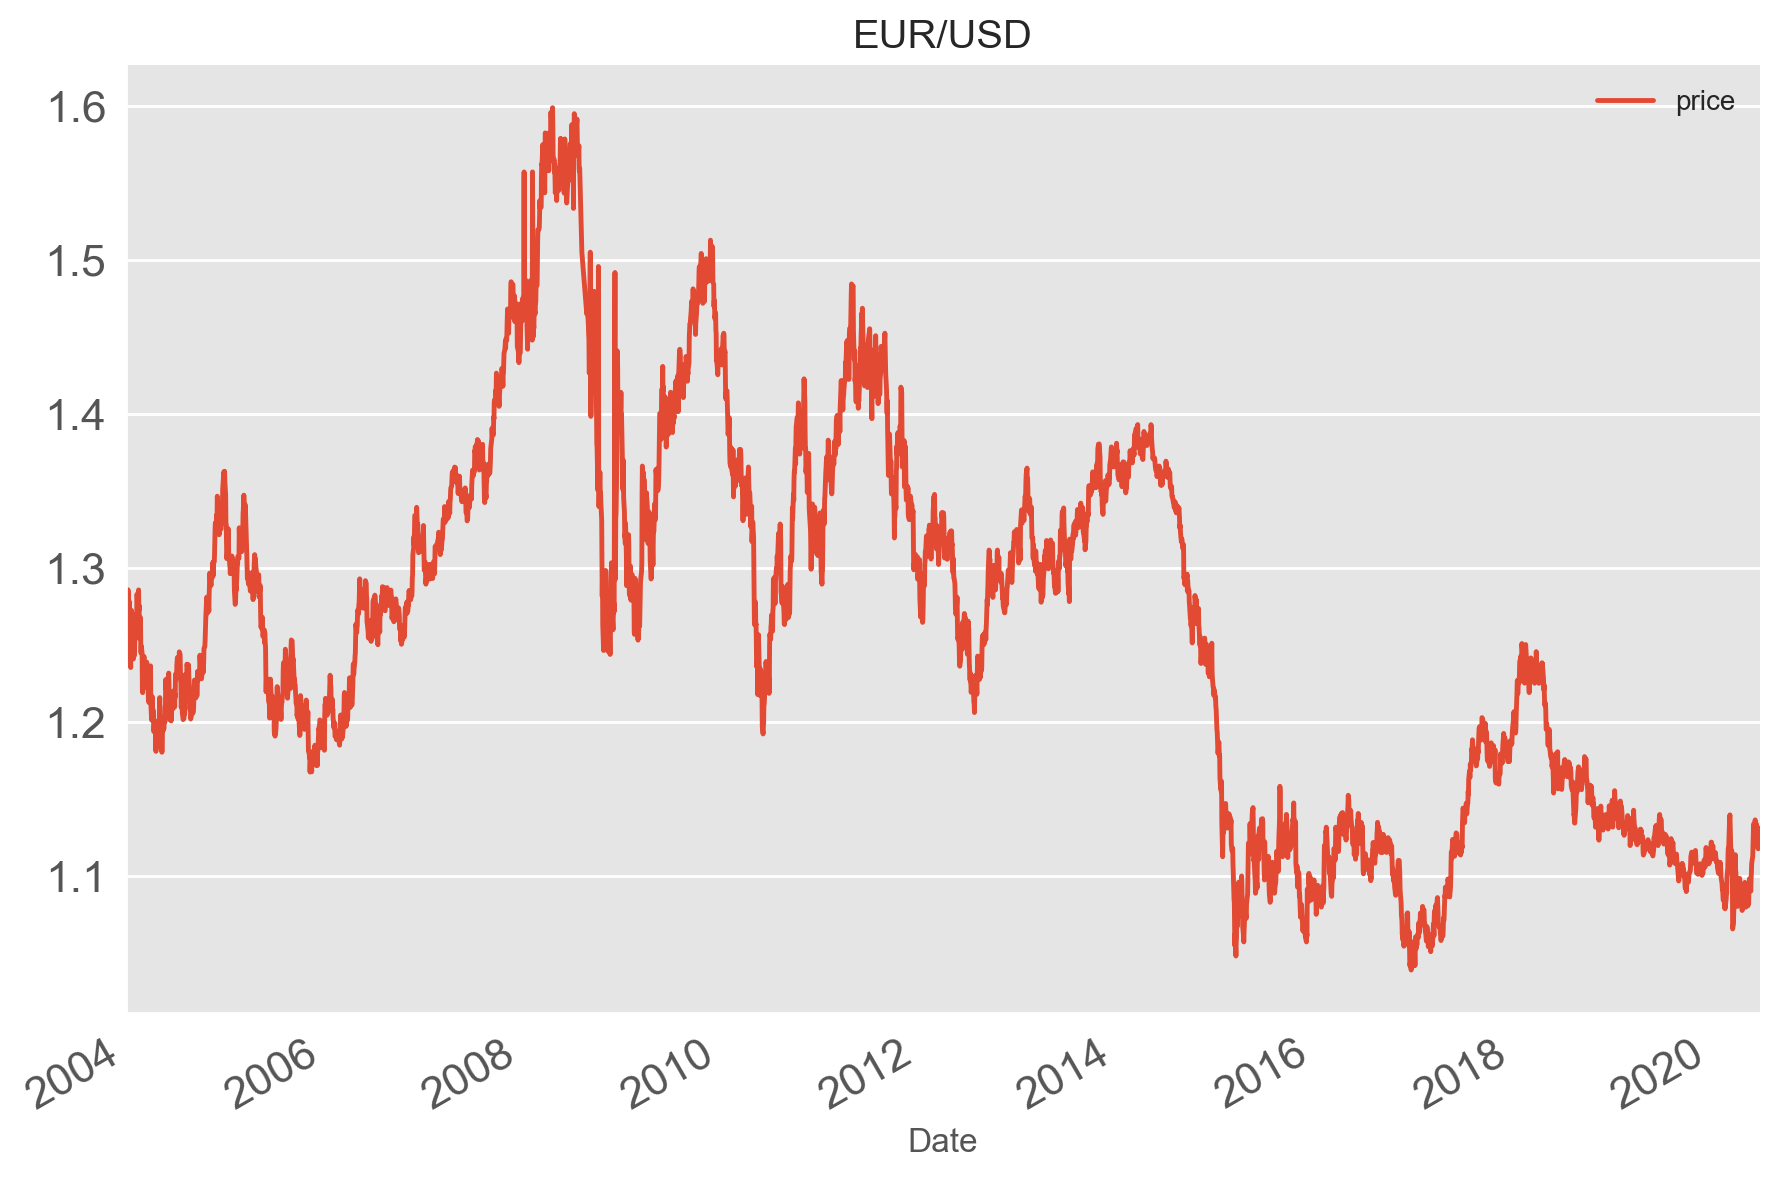

In [76]:
data.plot(figsize = (9, 6), title = "EUR/USD", fontsize = 16)
plt.gca().spines[["right" , "top"]].set_visible(False)
plt.autoscale(enable=True , axis ="x" , tight = True)
plt.grid(axis ="x")
plt.tight_layout()
plt.show()

## Defining an MACD Strategy (Part 1)

In [77]:
data

,price
Date,
2004-01-01,1.258194
2004-01-02,1.258194
2004-01-05,1.268698
2004-01-06,1.272103
2004-01-07,1.264095
...,...
2020-06-24,1.131235
2020-06-25,1.125087
2020-06-26,1.122208


In [78]:
ema_s = 12 # EMA Short
ema_l = 26 # EMA Long

In [79]:
data["EMA_S"] = data.price.ewm(span = ema_s , min_periods = ema_s).mean()
data["EMA_L"] = data.price.ewm(span = ema_l , min_periods = ema_l).mean()

In [80]:
data

,price,EMA_S,EMA_L
Date,,,
2004-01-01,1.258194,NaN,NaN
2004-01-02,1.258194,NaN,NaN
2004-01-05,1.268698,NaN,NaN
2004-01-06,1.272103,NaN,NaN
2004-01-07,1.264095,NaN,NaN
...,...,...,...
2020-06-24,1.131235,1.125123,1.117852
2020-06-25,1.125087,1.125118,1.118388
2020-06-26,1.122208,1.124670,1.118671


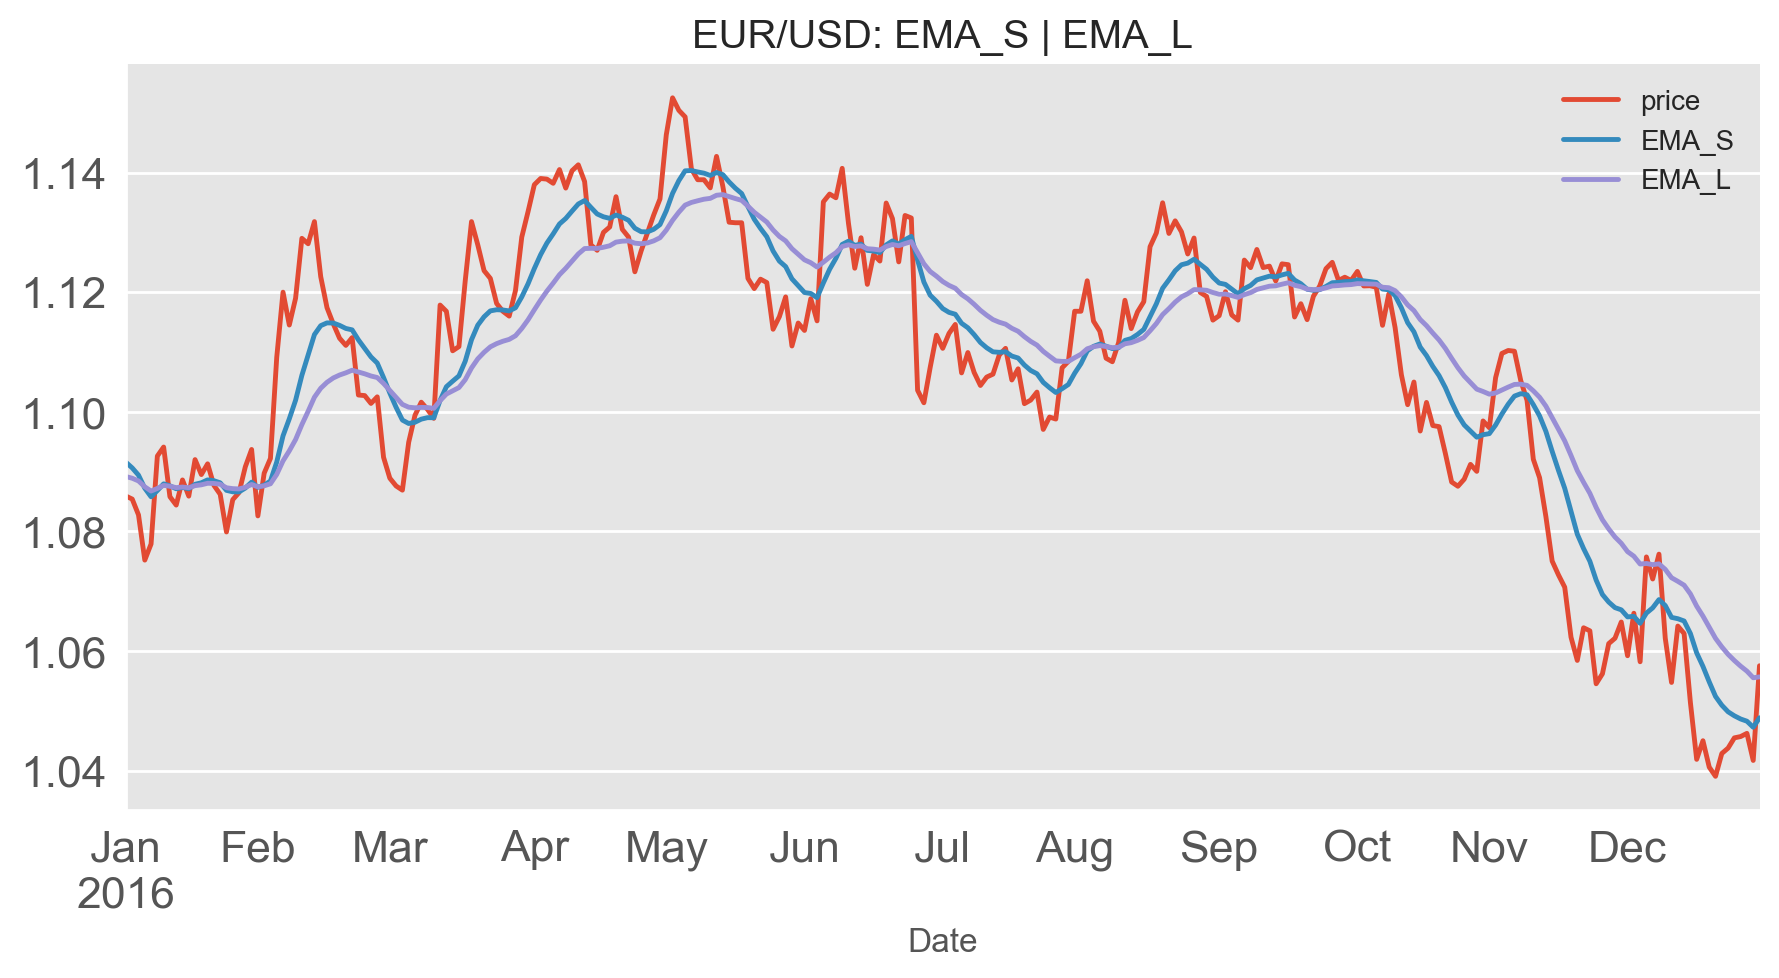

In [81]:
data.loc["2016", ["price", "EMA_S", "EMA_L"]].plot(title = "EUR/USD: EMA_S | EMA_L", fontsize = 16, figsize = (9, 5))
plt.gca().spines[["right" , "top"]].set_visible(False)
plt.autoscale(enable=True , axis ="x" , tight = True)
plt.grid(axis ="x")
plt.tight_layout()
plt.show()

In [82]:
data["MACD"] = data.EMA_S - data.EMA_L

In [83]:
data

,price,EMA_S,EMA_L,MACD
Date,,,,
2004-01-01,1.258194,NaN,NaN,NaN
2004-01-02,1.258194,NaN,NaN,NaN
2004-01-05,1.268698,NaN,NaN,NaN
2004-01-06,1.272103,NaN,NaN,NaN
2004-01-07,1.264095,NaN,NaN,NaN
...,...,...,...,...
2020-06-24,1.131235,1.125123,1.117852,0.007272
2020-06-25,1.125087,1.125118,1.118388,0.006730
2020-06-26,1.122208,1.124670,1.118671,0.005999


In [84]:
np.arange(start= -1 , stop = +1.5 , step = 0.5)

array([-1. , -0.5,  0. ,  0.5,  1. ])

In [85]:
data.loc['2016' , 'MACD'].describe()

count    261.000000
mean      -0.000695
std        0.005047
min       -0.012502
25%       -0.004608
50%       -0.000021
75%        0.002392
max        0.010471
Name: MACD, dtype: float64

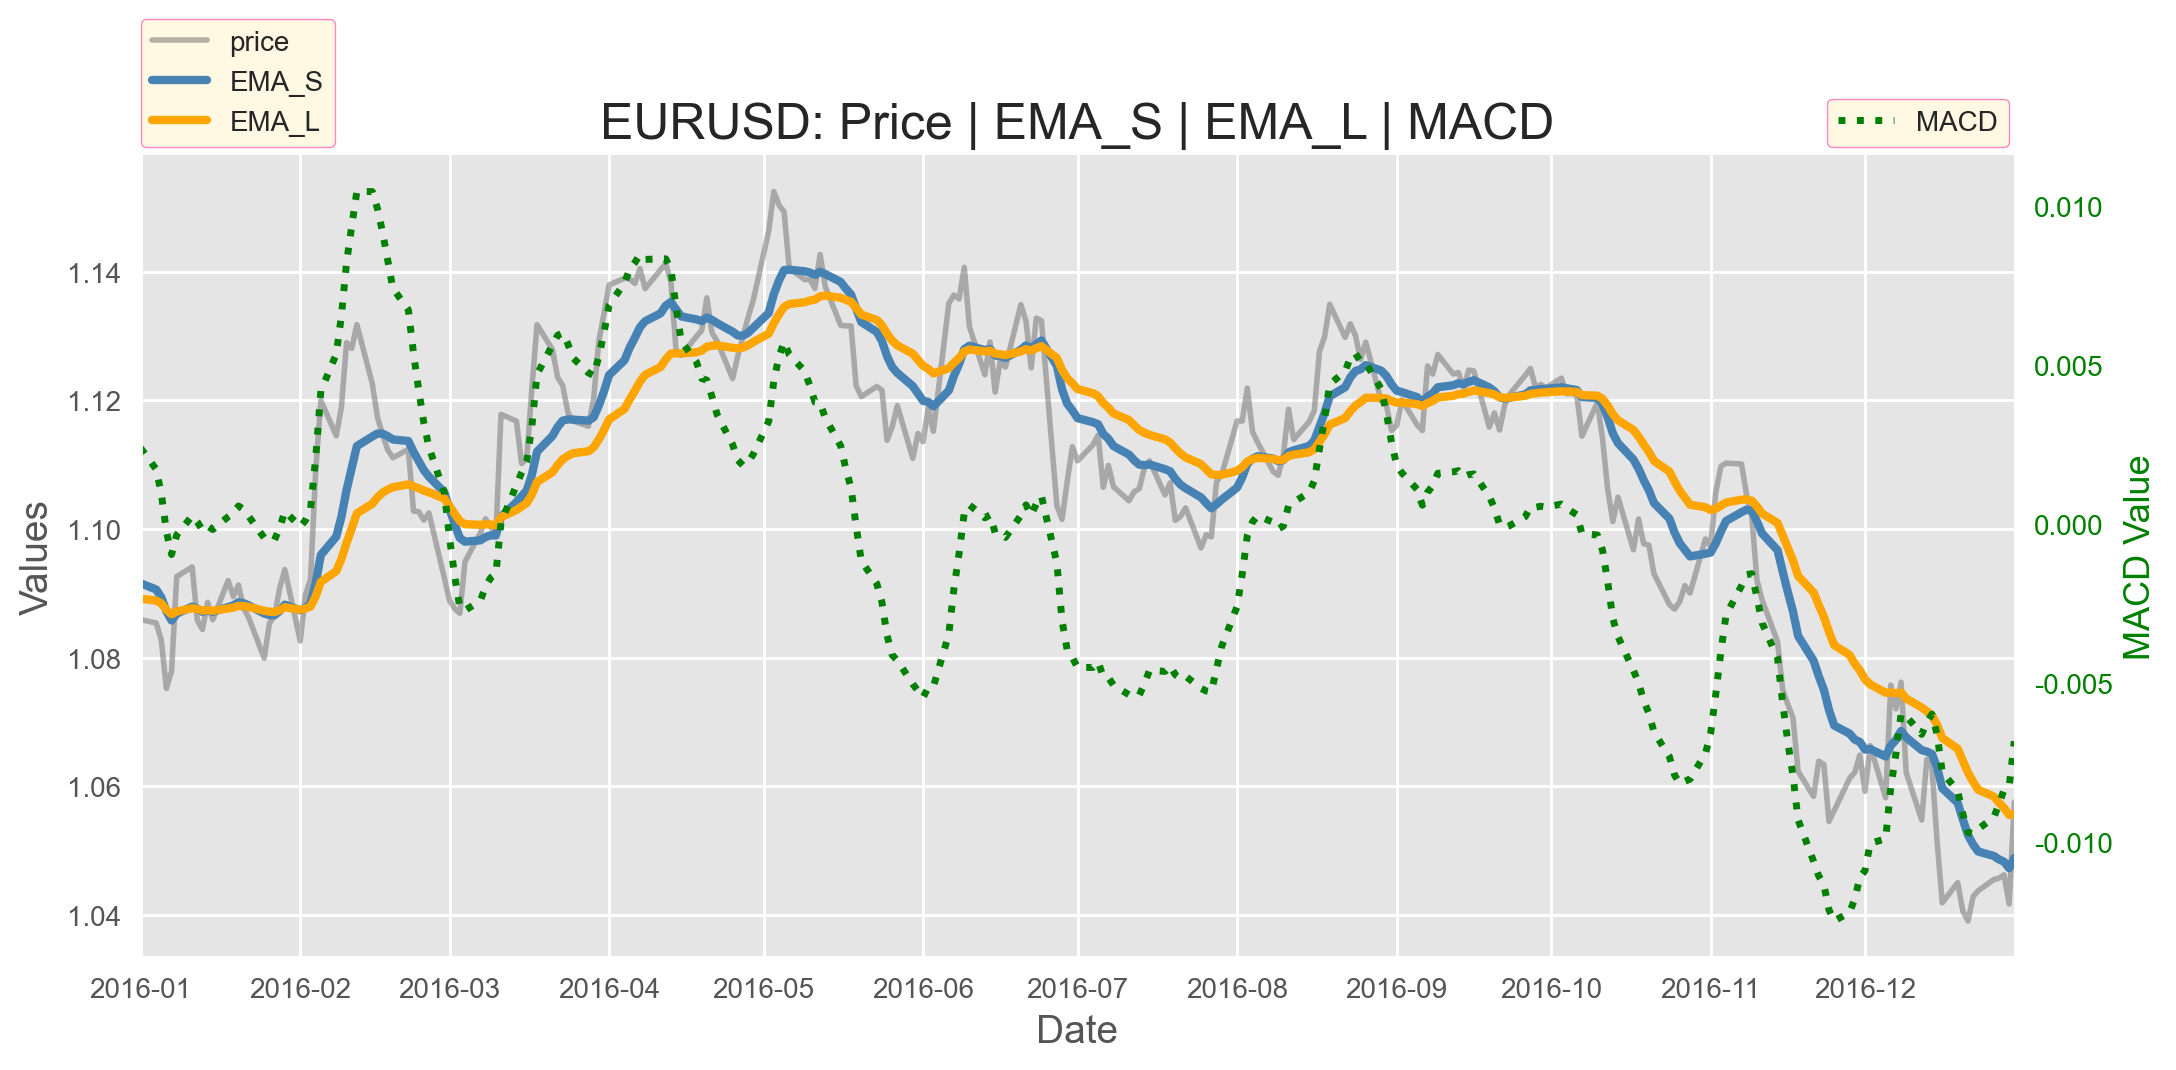

In [86]:
fig , ax = plt.subplots(figsize = (11,5.5))

ax.plot(data.loc['2016' , 'price'] , color = "gray" , lw = 2 , alpha = 0.6 , label = 'price')
ax.plot(data.loc['2016' , 'EMA_S'] , color = "steelblue" , lw = 3 , label = 'EMA_S')
ax.plot(data.loc['2016' , 'EMA_L'] , color = "orange" , lw = 3 , label = 'EMA_L')
ax.set_title("EURUSD: Price | EMA_S | EMA_L | MACD" , fontsize = 18)
ax.set_ylabel("Values" , fontsize = 14)
ax.set_xlabel("Date" , fontsize = 14)
ax.autoscale(enable=True , axis ="x" , tight = True)
ax.legend(loc = (0,1.01) , fancybox = True , shadow = False , frameon = True , facecolor = "cornsilk" , edgecolor = "hotpink")
fig.gca().spines[["right" , "top"]].set_visible(False)

ax2 = ax.twinx()
ax2.plot(data.loc['2016' , 'MACD'] , ls = ":" , color ="green" , lw = 2.5 , label = "MACD")
ax2.autoscale(enable=True , axis ="x" , tight = True)
ax2.set_ylabel("MACD Value" , color = "green" , fontsize =13)
ax2.set_yticks(ticks =  [-0.010 , -0.005 , 0.000 , 0.005 , 0.010] , 
               labels = ['-0.010' , '-0.005' , '0.000' , '0.005' , '0.010'] , color = "green")
ax2.legend(loc = (0.9,1.01) , fancybox = True , shadow = False , frameon = True , facecolor = "cornsilk" , edgecolor = "hotpink")

plt.gca().spines[["right" , "top"]].set_visible(False)
plt.grid(axis ="y")
plt.tight_layout()
plt.show()

In [87]:
signal_mw = 9 # Moving Window for Signal Line

In [88]:
data["MACD_Signal"] = data["MACD"].ewm(span = signal_mw , min_periods = signal_mw).mean()

In [89]:
data

,price,EMA_S,EMA_L,MACD,MACD_Signal
Date,,,,,
2004-01-01,1.258194,NaN,NaN,NaN,NaN
2004-01-02,1.258194,NaN,NaN,NaN,NaN
2004-01-05,1.268698,NaN,NaN,NaN,NaN
2004-01-06,1.272103,NaN,NaN,NaN,NaN
2004-01-07,1.264095,NaN,NaN,NaN,NaN
...,...,...,...,...,...
2020-06-24,1.131235,1.125123,1.117852,0.007272,0.008516
2020-06-25,1.125087,1.125118,1.118388,0.006730,0.008158
2020-06-26,1.122208,1.124670,1.118671,0.005999,0.007727


In [90]:
data.loc["2016"]

,price,EMA_S,EMA_L,MACD,MACD_Signal
Date,,,,,
2016-01-01,1.085906,1.091559,1.089167,0.002392,0.002641
2016-01-04,1.085399,1.090611,1.088888,0.001723,0.002458
2016-01-05,1.082755,1.089402,1.088433,0.000969,0.002160
2016-01-06,1.075199,1.087217,1.087453,-0.000236,0.001681
2016-01-07,1.077900,1.085784,1.086745,-0.000962,0.001152
...,...,...,...,...,...
2016-12-26,1.045478,1.049165,1.058405,-0.009240,-0.008833
2016-12-27,1.045697,1.048631,1.057464,-0.008832,-0.008833
2016-12-28,1.046233,1.048262,1.056632,-0.008370,-0.008740


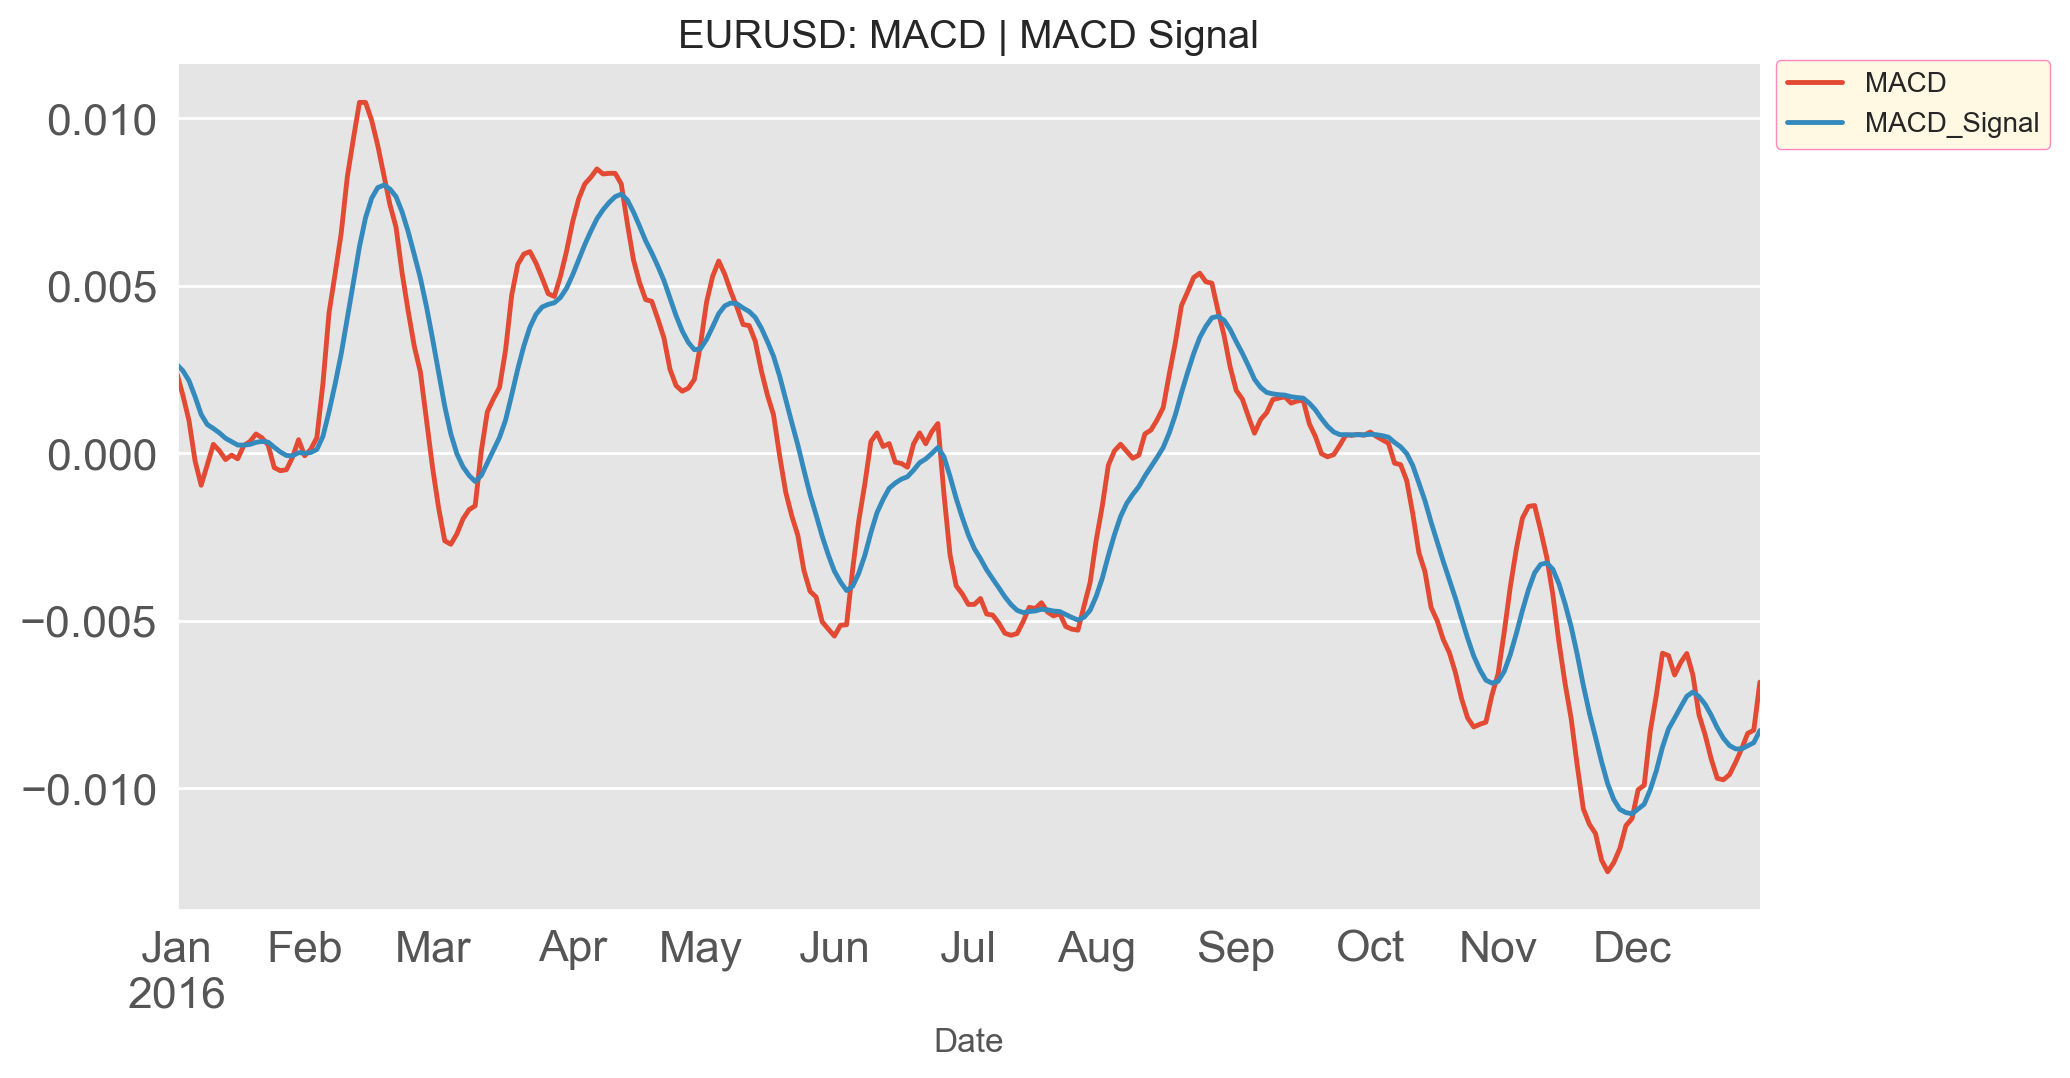

In [91]:
data.loc["2016", ["MACD", "MACD_Signal"]].plot(figsize = (9, 5.5) , title = "EURUSD: MACD | MACD Signal" , fontsize = 16)

plt.gca().spines[["right" , "top"]].set_visible(False)
plt.grid(axis ="x")
plt.tight_layout()
plt.legend(loc = (1.01,.9) , fancybox = True , shadow = False , frameon = True , facecolor = "cornsilk" , edgecolor = "hotpink")
plt.show()

## Defining an MACD Strategy (Part 2)

In [92]:
data["position"] = np.where(data["MACD"] - data["MACD_Signal"] > 0 , +1 , -1)

In [93]:
data

,price,EMA_S,EMA_L,MACD,MACD_Signal,position
Date,,,,,,
2004-01-01,1.258194,NaN,NaN,NaN,NaN,-1
2004-01-02,1.258194,NaN,NaN,NaN,NaN,-1
2004-01-05,1.268698,NaN,NaN,NaN,NaN,-1
2004-01-06,1.272103,NaN,NaN,NaN,NaN,-1
2004-01-07,1.264095,NaN,NaN,NaN,NaN,-1
...,...,...,...,...,...,...
2020-06-24,1.131235,1.125123,1.117852,0.007272,0.008516,-1
2020-06-25,1.125087,1.125118,1.118388,0.006730,0.008158,-1
2020-06-26,1.122208,1.124670,1.118671,0.005999,0.007727,-1


In [94]:
data["position"].value_counts(normalize=True)*100

 1    50.760234
-1    49.239766
Name: position, dtype: float64

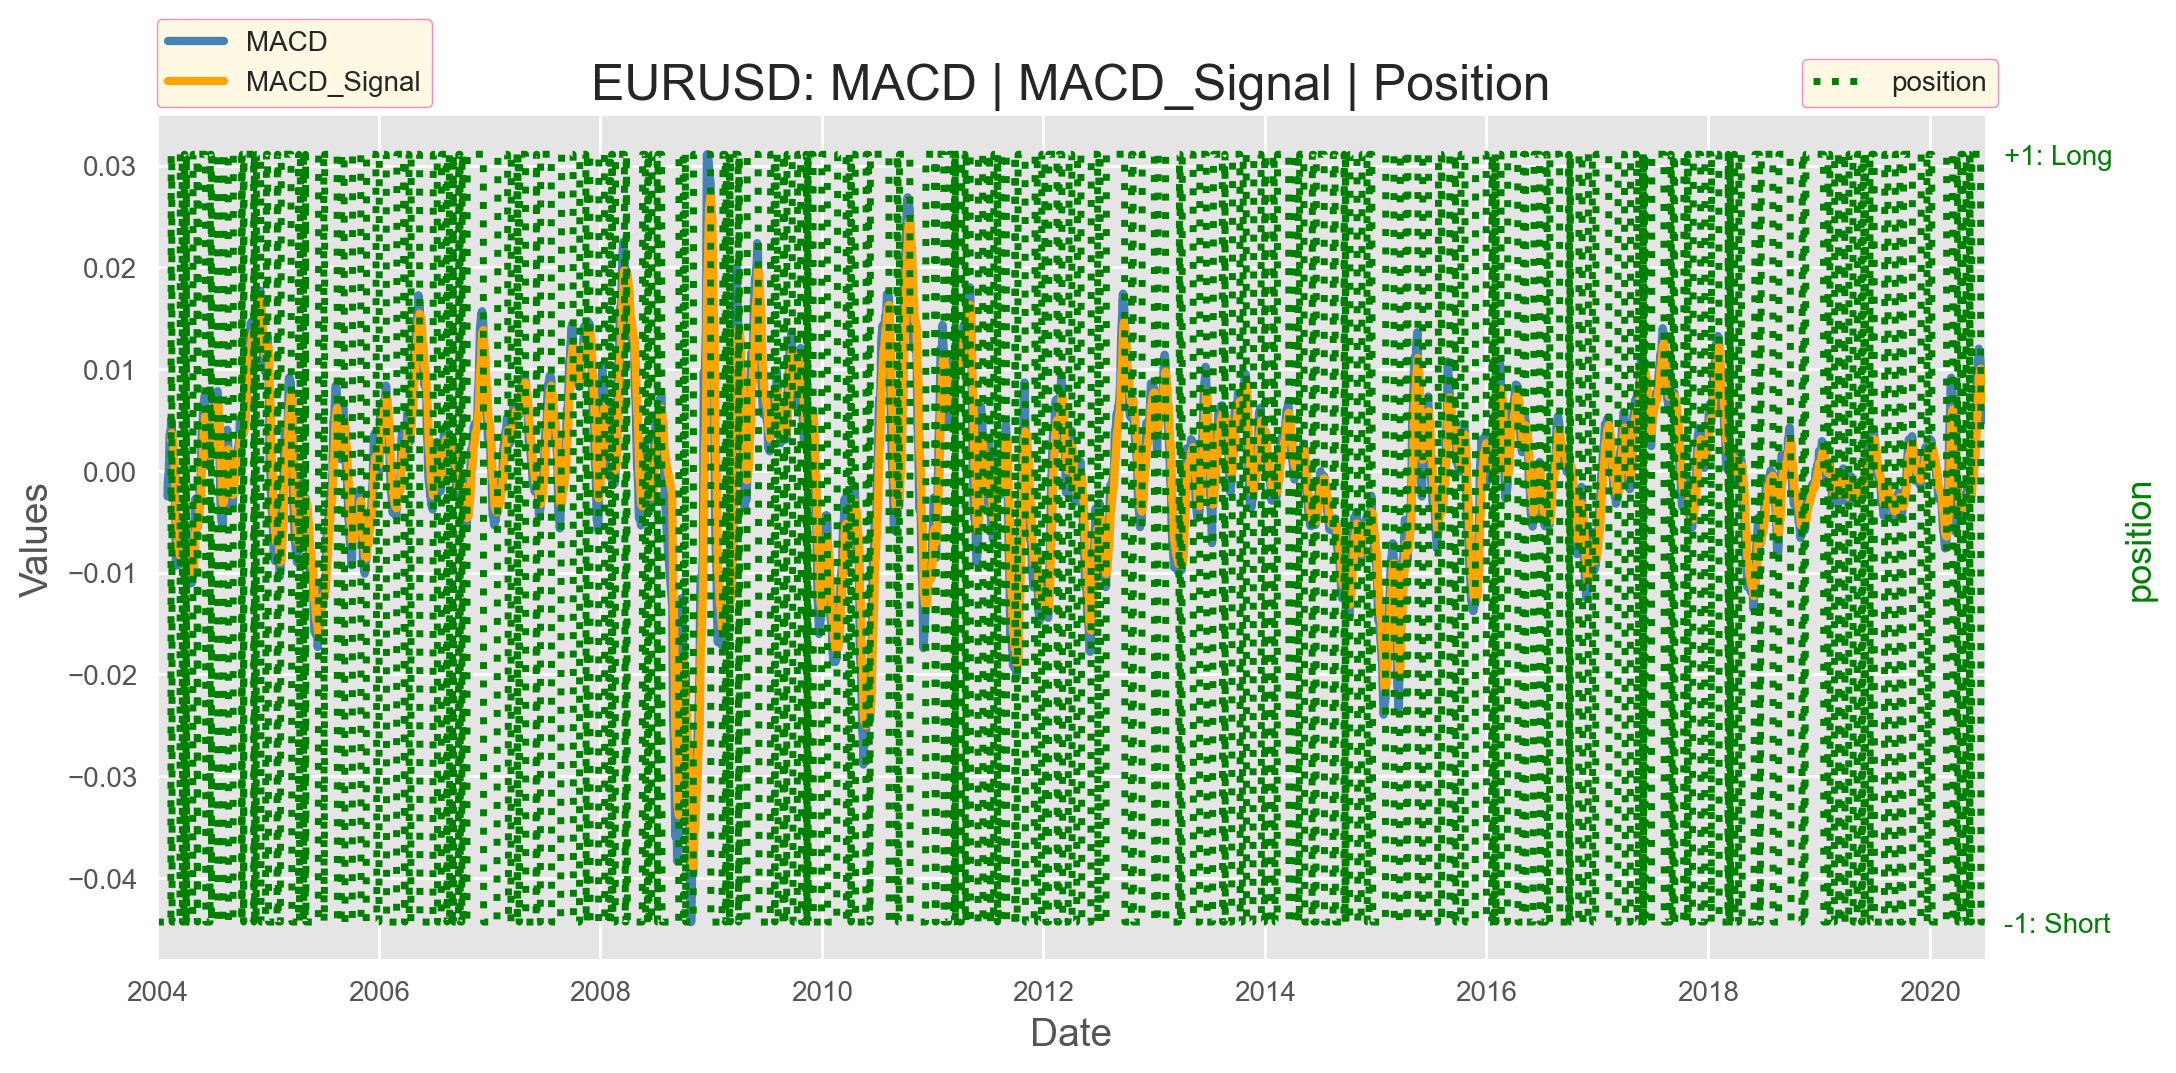

In [95]:
fig , ax = plt.subplots(figsize = (11,5.5))

ax.plot(data.loc[: , 'MACD'] , color = "steelblue" , lw = 3 , label = 'MACD')
ax.plot(data.loc[: , 'MACD_Signal'] , color = "orange" , lw = 3 , label = 'MACD_Signal')
ax.set_title("EURUSD: MACD | MACD_Signal | Position" , fontsize = 18)
ax.set_ylabel("Values" , fontsize = 14)
ax.set_xlabel("Date" , fontsize = 14)
ax.autoscale(enable=True , axis ="x" , tight = True)
ax.legend(loc = (0,1.01) , fancybox = True , shadow = False , frameon = True , facecolor = "cornsilk" , edgecolor = "hotpink")
fig.gca().spines[["right" , "top"]].set_visible(False)

ax2 = ax.twinx()
ax2.plot(data.loc[: , 'position'] , ls = ":" , color ="green" , lw = 2.5 , label = "position")
ax2.autoscale(enable=True , axis ="x" , tight = True)
ax2.set_ylabel("position" , color = "green" , fontsize =13)
ax2.set_yticks(ticks =  [-1 , +1] , 
               labels = ['-1: Short' , '+1: Long'] , color = "green")
ax2.legend(loc = (0.9,1.01) , fancybox = True , shadow = False , frameon = True , facecolor = "cornsilk" , edgecolor = "hotpink")

plt.gca().spines[["right" , "top"]].set_visible(False)
plt.grid(axis ="y")
plt.tight_layout()
plt.show()

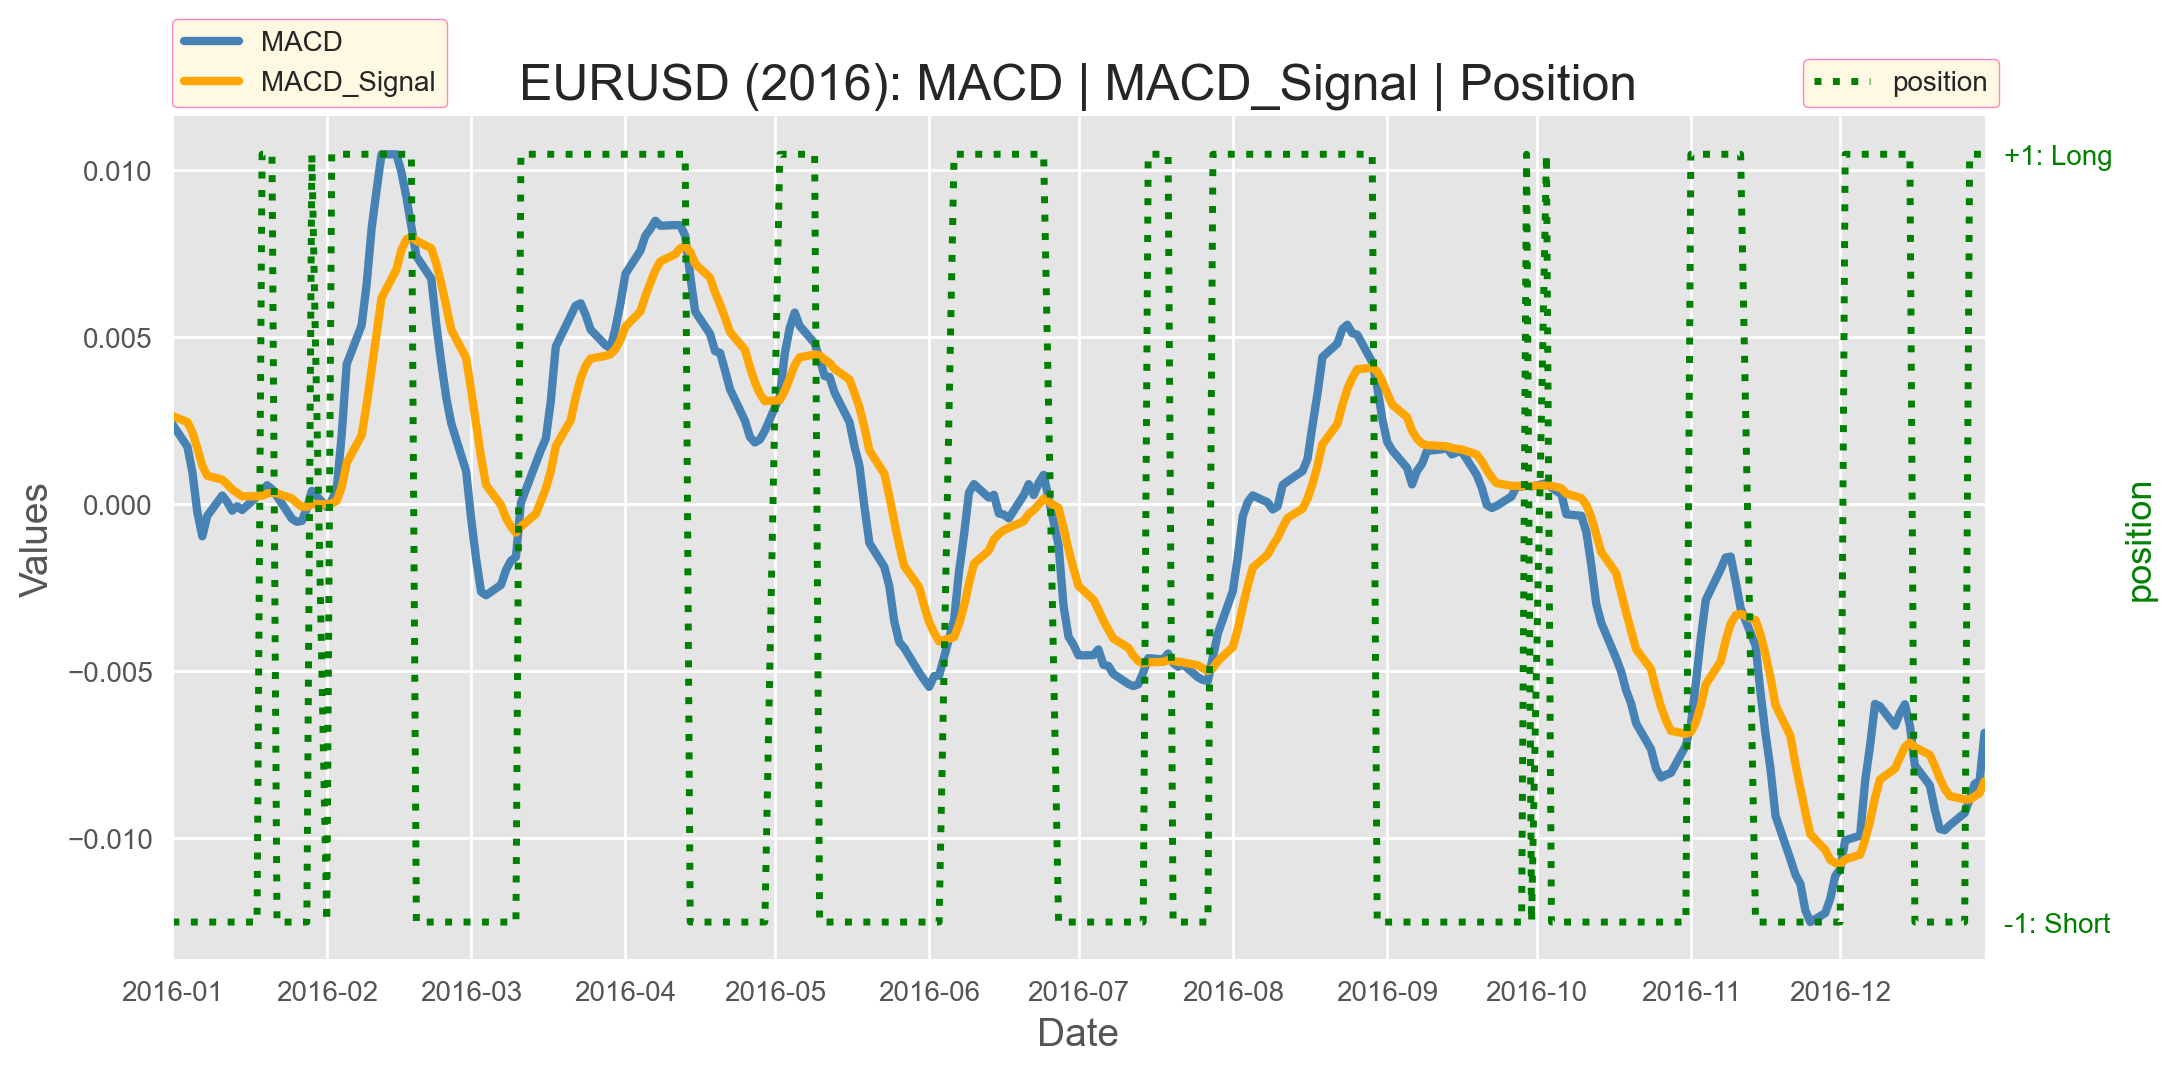

In [96]:
fig , ax = plt.subplots(figsize = (11,5.5))

ax.plot(data.loc['2016' , 'MACD'] , color = "steelblue" , lw = 3 , label = 'MACD')
ax.plot(data.loc['2016' , 'MACD_Signal'] , color = "orange" , lw = 3 , label = 'MACD_Signal')
ax.set_title("EURUSD (2016): MACD | MACD_Signal | Position" , fontsize = 18)
ax.set_ylabel("Values" , fontsize = 14)
ax.set_xlabel("Date" , fontsize = 14)
ax.autoscale(enable=True , axis ="x" , tight = True)
ax.legend(loc = (0,1.01) , fancybox = True , shadow = False , frameon = True , facecolor = "cornsilk" , edgecolor = "hotpink")
fig.gca().spines[["right" , "top"]].set_visible(False)

ax2 = ax.twinx()
ax2.plot(data.loc['2016' , 'position'] , ls = ":" , color ="green" , lw = 2.5 , label = "position")
ax2.autoscale(enable=True , axis ="x" , tight = True)
ax2.set_ylabel("position" , color = "green" , fontsize =13)
ax2.set_yticks(ticks =  [-1 , +1] , 
               labels = ['-1: Short' , '+1: Long'] , color = "green")
ax2.legend(loc = (0.9,1.01) , fancybox = True , shadow = False , frameon = True , facecolor = "cornsilk" , edgecolor = "hotpink")

plt.gca().spines[["right" , "top"]].set_visible(False)
plt.grid(axis ="y")
plt.tight_layout()
plt.show()

## Vectorized Strategy Backtesting

In [97]:
data

,price,EMA_S,EMA_L,MACD,MACD_Signal,position
Date,,,,,,
2004-01-01,1.258194,NaN,NaN,NaN,NaN,-1
2004-01-02,1.258194,NaN,NaN,NaN,NaN,-1
2004-01-05,1.268698,NaN,NaN,NaN,NaN,-1
2004-01-06,1.272103,NaN,NaN,NaN,NaN,-1
2004-01-07,1.264095,NaN,NaN,NaN,NaN,-1
...,...,...,...,...,...,...
2020-06-24,1.131235,1.125123,1.117852,0.007272,0.008516,-1
2020-06-25,1.125087,1.125118,1.118388,0.006730,0.008158,-1
2020-06-26,1.122208,1.124670,1.118671,0.005999,0.007727,-1


In [98]:
data["log_ret"] = np.log(data["price"]/data["price"].shift(1))

In [99]:
data

,price,EMA_S,EMA_L,MACD,MACD_Signal,position,log_ret
Date,,,,,,,
2004-01-01,1.258194,NaN,NaN,NaN,NaN,-1,NaN
2004-01-02,1.258194,NaN,NaN,NaN,NaN,-1,0.000000
2004-01-05,1.268698,NaN,NaN,NaN,NaN,-1,0.008313
2004-01-06,1.272103,NaN,NaN,NaN,NaN,-1,0.002681
2004-01-07,1.264095,NaN,NaN,NaN,NaN,-1,-0.006315
...,...,...,...,...,...,...,...
2020-06-24,1.131235,1.125123,1.117852,0.007272,0.008516,-1,0.002892
2020-06-25,1.125087,1.125118,1.118388,0.006730,0.008158,-1,-0.005449
2020-06-26,1.122208,1.124670,1.118671,0.005999,0.007727,-1,-0.002562


In [100]:
data = data.dropna()

In [101]:
data

,price,EMA_S,EMA_L,MACD,MACD_Signal,position,log_ret
Date,,,,,,,
2004-02-17,1.285793,1.271256,1.266191,0.005065,0.003018,1,0.007251
2004-02-18,1.272508,1.271449,1.266693,0.004756,0.003408,1,-0.010386
2004-02-19,1.275705,1.272106,1.267405,0.004700,0.003691,1,0.002510
2004-02-20,1.254202,1.269345,1.266367,0.002978,0.003538,-1,-0.017000
2004-02-23,1.257197,1.267473,1.265649,0.001824,0.003175,-1,0.002386
...,...,...,...,...,...,...,...
2020-06-24,1.131235,1.125123,1.117852,0.007272,0.008516,-1,0.002892
2020-06-25,1.125087,1.125118,1.118388,0.006730,0.008158,-1,-0.005449
2020-06-26,1.122208,1.124670,1.118671,0.005999,0.007727,-1,-0.002562


In [102]:
data["strategy"] = data["position"].shift(1) * data["log_ret"]

In [103]:
data

,price,EMA_S,EMA_L,MACD,MACD_Signal,position,log_ret,strategy
Date,,,,,,,,
2004-02-17,1.285793,1.271256,1.266191,0.005065,0.003018,1,0.007251,NaN
2004-02-18,1.272508,1.271449,1.266693,0.004756,0.003408,1,-0.010386,-0.010386
2004-02-19,1.275705,1.272106,1.267405,0.004700,0.003691,1,0.002510,0.002510
2004-02-20,1.254202,1.269345,1.266367,0.002978,0.003538,-1,-0.017000,-0.017000
2004-02-23,1.257197,1.267473,1.265649,0.001824,0.003175,-1,0.002386,-0.002386
...,...,...,...,...,...,...,...,...
2020-06-24,1.131235,1.125123,1.117852,0.007272,0.008516,-1,0.002892,-0.002892
2020-06-25,1.125087,1.125118,1.118388,0.006730,0.008158,-1,-0.005449,0.005449
2020-06-26,1.122208,1.124670,1.118671,0.005999,0.007727,-1,-0.002562,0.002562


In [104]:
data = data.dropna()

In [105]:
ptc = 0.00007

In [106]:
data["trades"] = data["position"].diff().fillna(0).abs()

In [107]:
data.trades.value_counts(normalize=True)*100

0.0    91.110587
2.0     8.889413
Name: trades, dtype: float64

In [108]:
data["strategy_net"] = data["strategy"] - data["trades"] * ptc

In [109]:
data["cum_log_ret"] = np.exp(data["log_ret"].cumsum())
data["cum_strategy"] = np.exp(data["strategy"].cumsum())
data["cum_strategy_net"] = np.exp(data["strategy_net"].cumsum())

In [110]:
data

,price,EMA_S,EMA_L,MACD,MACD_Signal,position,log_ret,strategy,trades,strategy_net,cum_log_ret,cum_strategy,cum_strategy_net
Date,,,,,,,,,,,,,
2004-02-18,1.272508,1.271449,1.266693,0.004756,0.003408,1,-0.010386,-0.010386,0.0,-0.010386,0.989667,0.989667,0.989667
2004-02-19,1.275705,1.272106,1.267405,0.004700,0.003691,1,0.002510,0.002510,0.0,0.002510,0.992154,0.992154,0.992154
2004-02-20,1.254202,1.269345,1.266367,0.002978,0.003538,-1,-0.017000,-0.017000,2.0,-0.017140,0.975430,0.975430,0.975294
2004-02-23,1.257197,1.267473,1.265649,0.001824,0.003175,-1,0.002386,-0.002386,0.0,-0.002386,0.977760,0.973106,0.972969
2004-02-24,1.267797,1.267523,1.265817,0.001706,0.002868,-1,0.008395,-0.008395,0.0,-0.008395,0.986003,0.964970,0.964835
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2020-06-24,1.131235,1.125123,1.117852,0.007272,0.008516,-1,0.002892,-0.002892,0.0,-0.002892,0.879795,0.436655,0.414206
2020-06-25,1.125087,1.125118,1.118388,0.006730,0.008158,-1,-0.005449,0.005449,0.0,0.005449,0.875014,0.439041,0.416470
2020-06-26,1.122208,1.124670,1.118671,0.005999,0.007727,-1,-0.002562,0.002562,0.0,0.002562,0.872775,0.440168,0.417538


In [111]:
data.columns

Index(['price', 'EMA_S', 'EMA_L', 'MACD', 'MACD_Signal', 'position', 'log_ret',
       'strategy', 'trades', 'strategy_net', 'cum_log_ret', 'cum_strategy',
       'cum_strategy_net'],
      dtype='object')

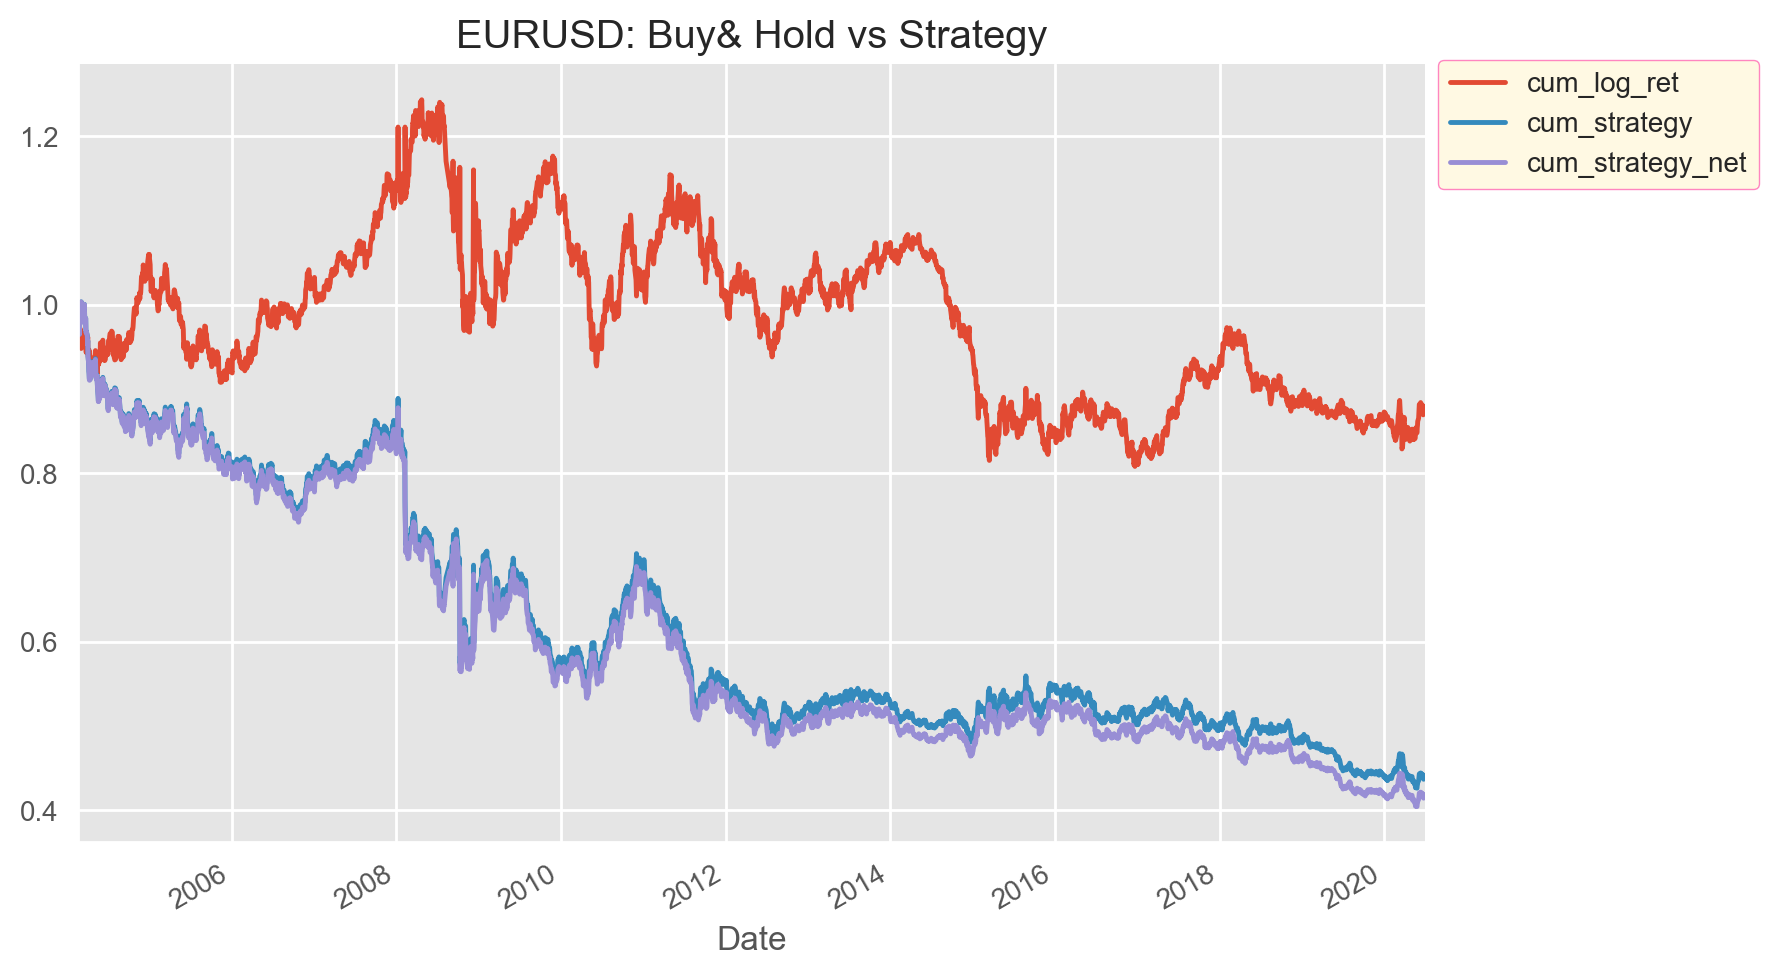

In [112]:
data[["cum_log_ret", "cum_strategy", "cum_strategy_net"]].plot(figsize = (9 , 5) , title = "EURUSD: Buy& Hold vs Strategy")
plt.autoscale(enable=True , axis ="x" , tight = True)
plt.legend(loc = (1.01,.84) , fancybox = True , shadow = False , frameon = True , facecolor = "cornsilk" , edgecolor = "hotpink")
plt.gca().spines[["right" , "top"]].set_visible(False)
plt.tight_layout()
plt.show()

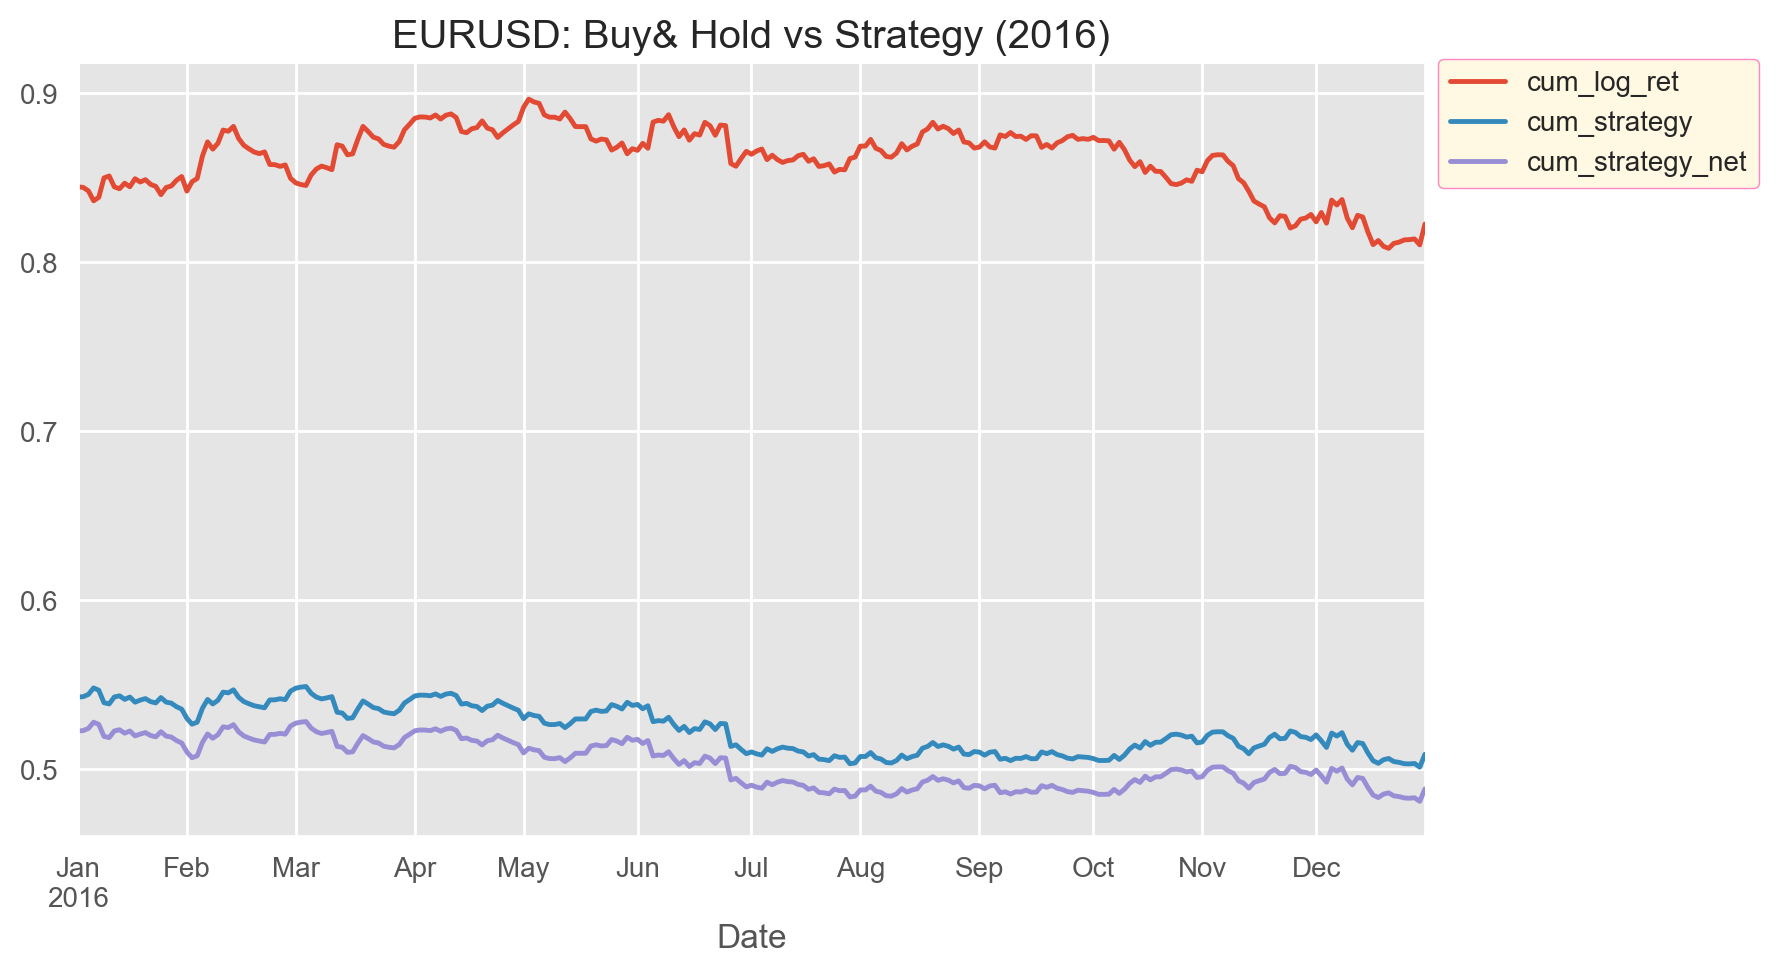

In [113]:
data.loc['2016' , ["cum_log_ret", "cum_strategy", "cum_strategy_net"]].plot(figsize = (9 , 5) , title = "EURUSD: Buy& Hold vs Strategy (2016)")
plt.autoscale(enable=True , axis ="x" , tight = True)
plt.legend(loc = (1.01,.84) , fancybox = True , shadow = False , frameon = True , facecolor = "cornsilk" , edgecolor = "hotpink")
plt.gca().spines[["right" , "top"]].set_visible(False)
plt.tight_layout()
plt.show()

## Using the MACDBacktester Class

In [114]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brute
plt.style.use("ggplot")
%config InlineBackend.figure_format ="retina"

In [115]:
pd.read_csv("forex_pairs.csv")

,Date,AUDEUR=X,EURUSD=X,USDGBP=X
0,2004-01-01,0.59780,1.258194,0.56016
1,2004-01-02,0.60314,1.258194,0.55751
2,2004-01-05,0.60467,1.268698,0.55334
3,2004-01-06,0.60350,1.272103,0.54906
4,2004-01-07,0.60728,1.264095,0.55012
...,...,...,...,...
4290,2020-06-24,0.61349,1.131235,0.79841
4291,2020-06-25,0.60938,1.125087,0.80561
4292,2020-06-26,0.61373,1.122208,0.80480
4293,2020-06-29,0.61128,1.122586,0.81023


In [116]:
from MACDBacktester import MACDBacktester as MACD

In [117]:
ptc = 0.00007

In [118]:
tester = MACD("EURUSD=X", EMA_S = 12, EMA_L = 26, signal_mw = 9,
              start = "2004-01-01", end = "2020-06-30", tc = ptc)

In [119]:
tester

MACDBacktester(symbol = EURUSD=X, MACD(12, 26, 9), start = 2004-01-01, end = 2020-06-30)

In [120]:
tester.data

,price,returns,EMA_S,EMA_L,MACD,MACD_Signal
Date,,,,,,
2004-01-01,1.258194,NaN,NaN,NaN,NaN,NaN
2004-01-02,1.258194,0.000000,NaN,NaN,NaN,NaN
2004-01-05,1.268698,0.008313,NaN,NaN,NaN,NaN
2004-01-06,1.272103,0.002681,NaN,NaN,NaN,NaN
2004-01-07,1.264095,-0.006315,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...
2020-06-24,1.131235,0.002892,1.125123,1.117852,0.007272,0.008516
2020-06-25,1.125087,-0.005449,1.125118,1.118388,0.006730,0.008158
2020-06-26,1.122208,-0.002562,1.124670,1.118671,0.005999,0.007727


In [121]:
tester.test_strategy()

(0.416605, -0.458123)

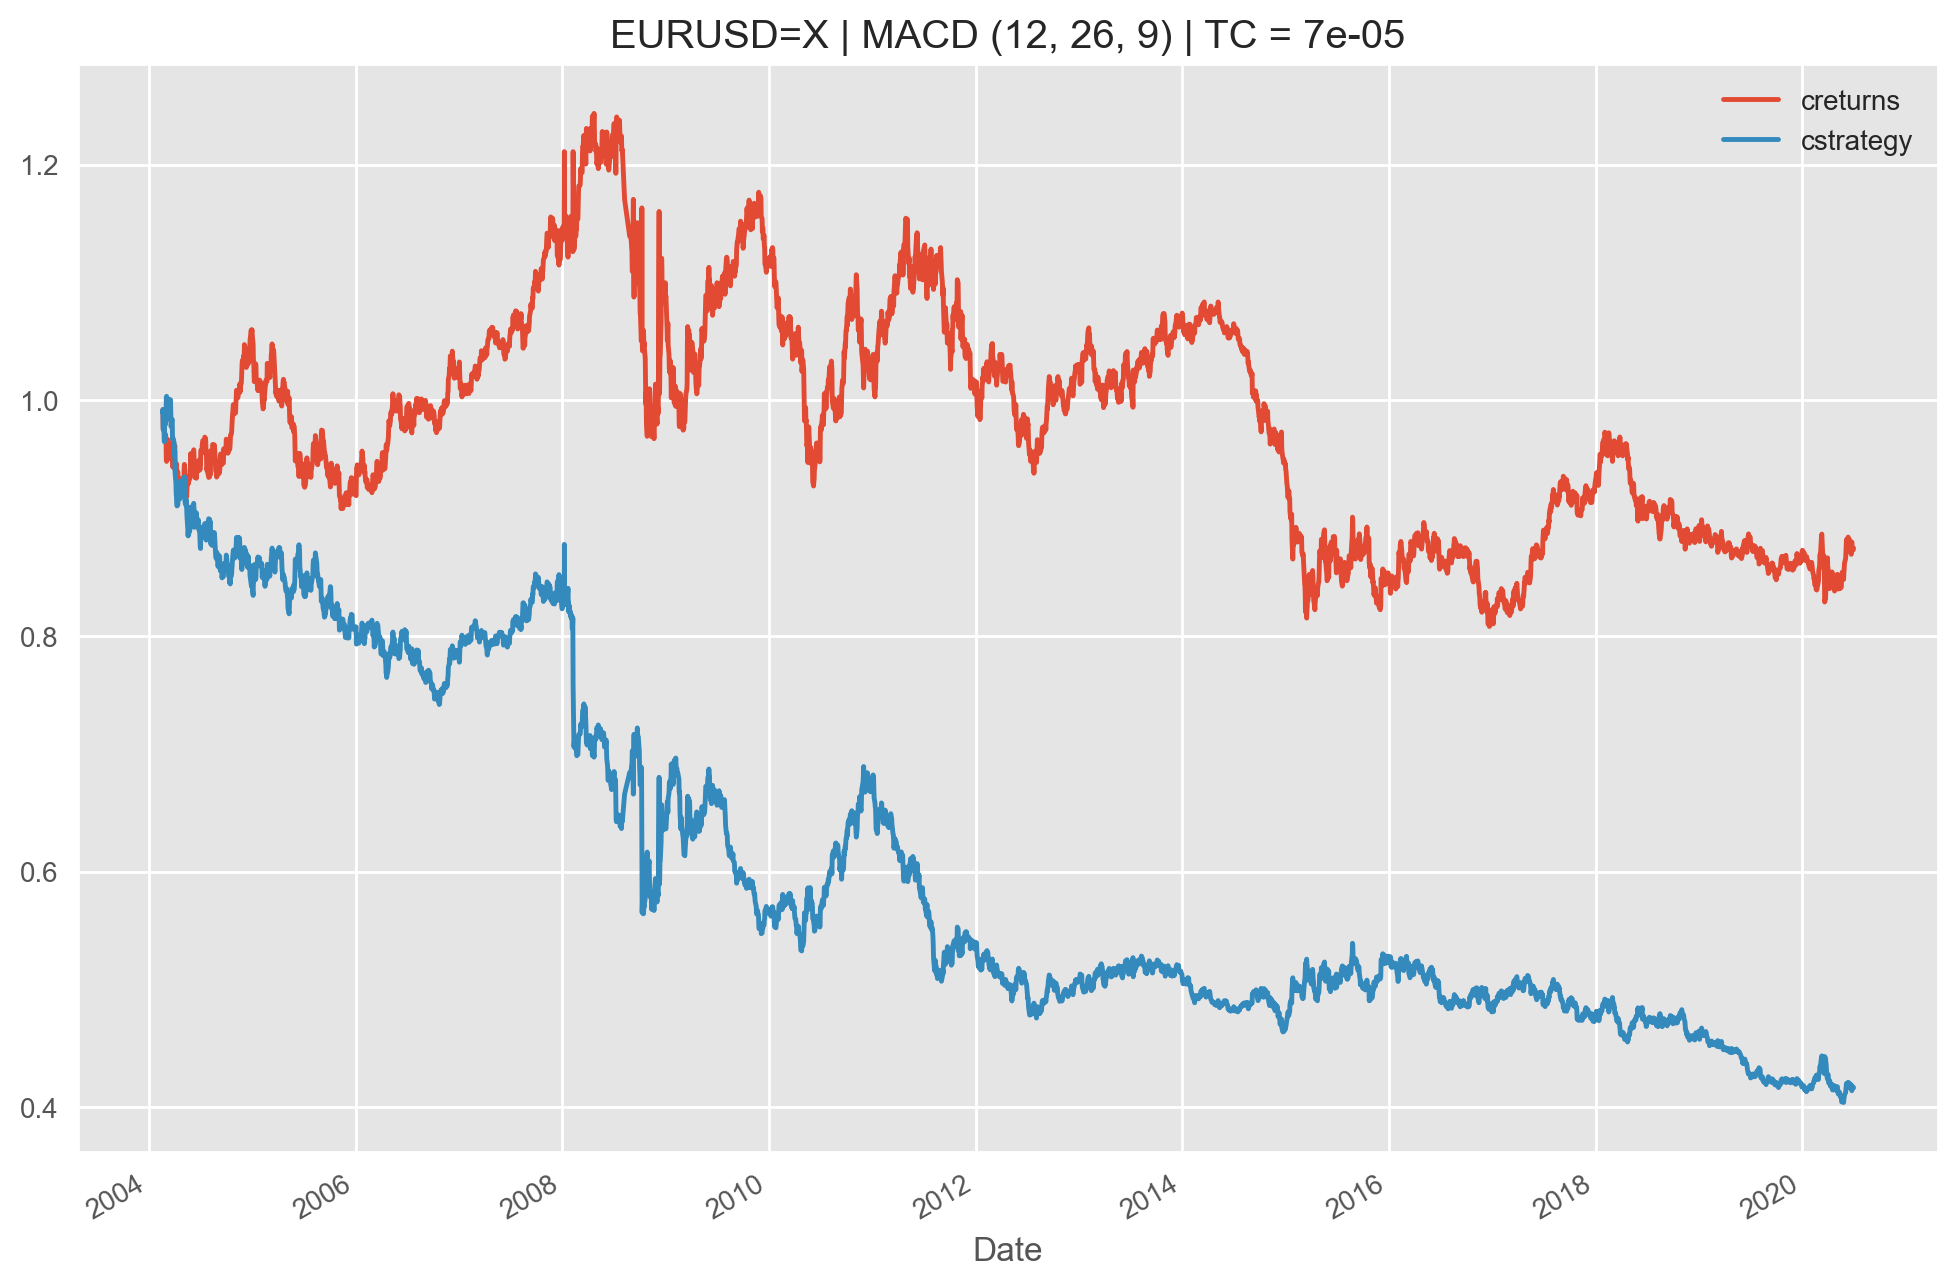

In [122]:
tester.plot_results()

In [123]:
tester.results

,price,returns,EMA_S,EMA_L,MACD,MACD_Signal,position,strategy,trades,creturns,cstrategy
Date,,,,,,,,,,,
2004-02-18,1.272508,-0.010386,1.271449,1.266693,0.004756,0.003408,1,-0.010386,0.0,0.989667,0.989667
2004-02-19,1.275705,0.002510,1.272106,1.267405,0.004700,0.003691,1,0.002510,0.0,0.992154,0.992154
2004-02-20,1.254202,-0.017000,1.269345,1.266367,0.002978,0.003538,-1,-0.017140,2.0,0.975430,0.975294
2004-02-23,1.257197,0.002386,1.267473,1.265649,0.001824,0.003175,-1,-0.002386,0.0,0.977760,0.972969
2004-02-24,1.267797,0.008395,1.267523,1.265817,0.001706,0.002868,-1,-0.008395,0.0,0.986003,0.964835
...,...,...,...,...,...,...,...,...,...,...,...
2020-06-24,1.131235,0.002892,1.125123,1.117852,0.007272,0.008516,-1,-0.002892,0.0,0.879795,0.414206
2020-06-25,1.125087,-0.005449,1.125118,1.118388,0.006730,0.008158,-1,0.005449,0.0,0.875014,0.416470
2020-06-26,1.122208,-0.002562,1.124670,1.118671,0.005999,0.007727,-1,0.002562,0.0,0.872775,0.417538


In [124]:
tester.optimize_parameters((5, 20, 1), (21, 50, 1), (5, 20, 1))

(array([18., 30., 19.]), 0.760579)

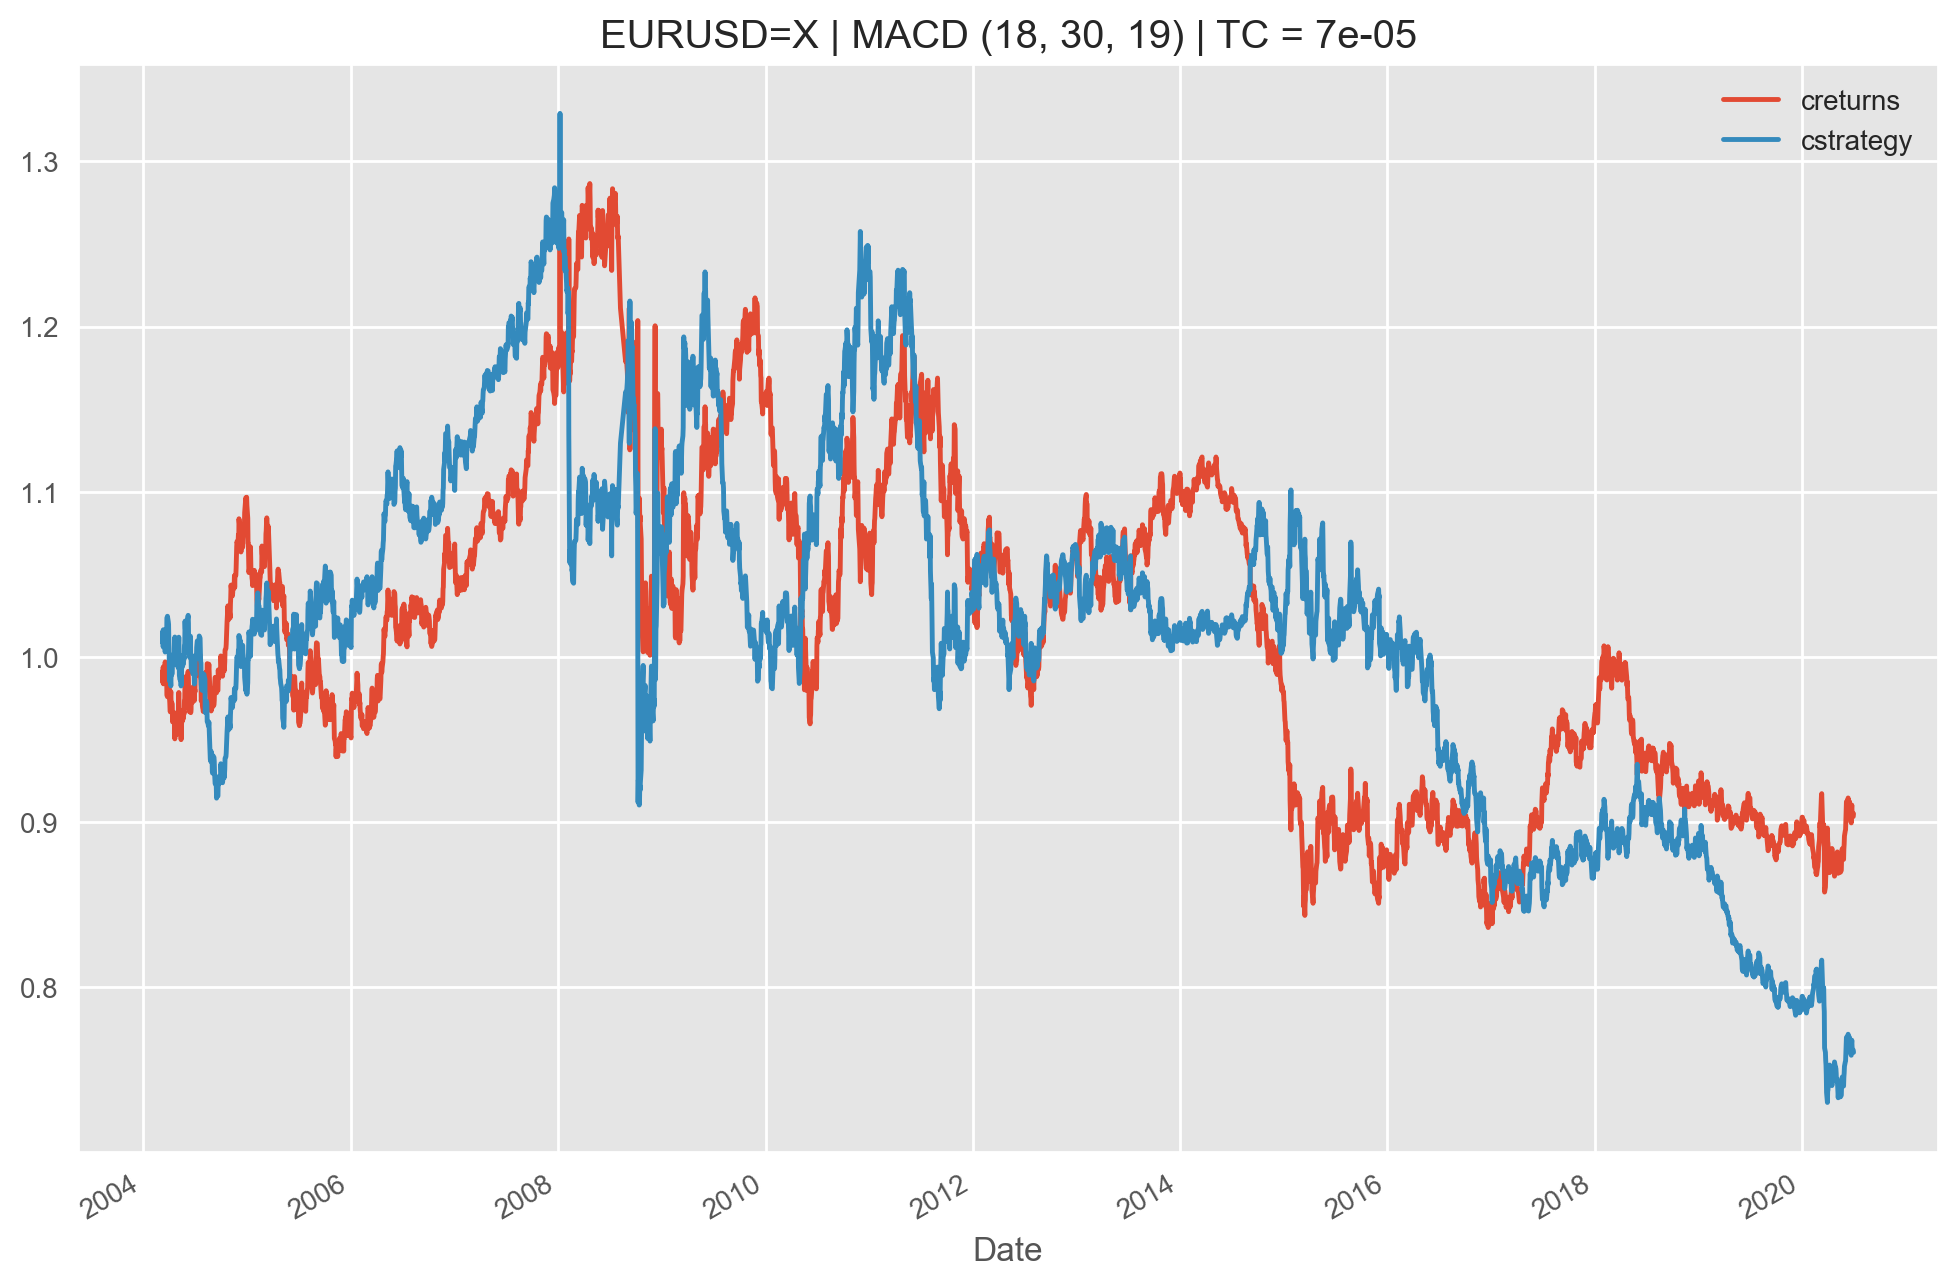

In [125]:
tester.plot_results()

__AUD / EUR__

In [127]:
tester = MACD("AUDEUR=X", 
              EMA_S = 12, 
              EMA_L = 26, 
              signal_mw = 9, 
              start = "2004-01-01", 
              end = "2020-06-30", 
              tc = 0)

In [128]:
tester.test_strategy()

(1.061038, 0.076032)

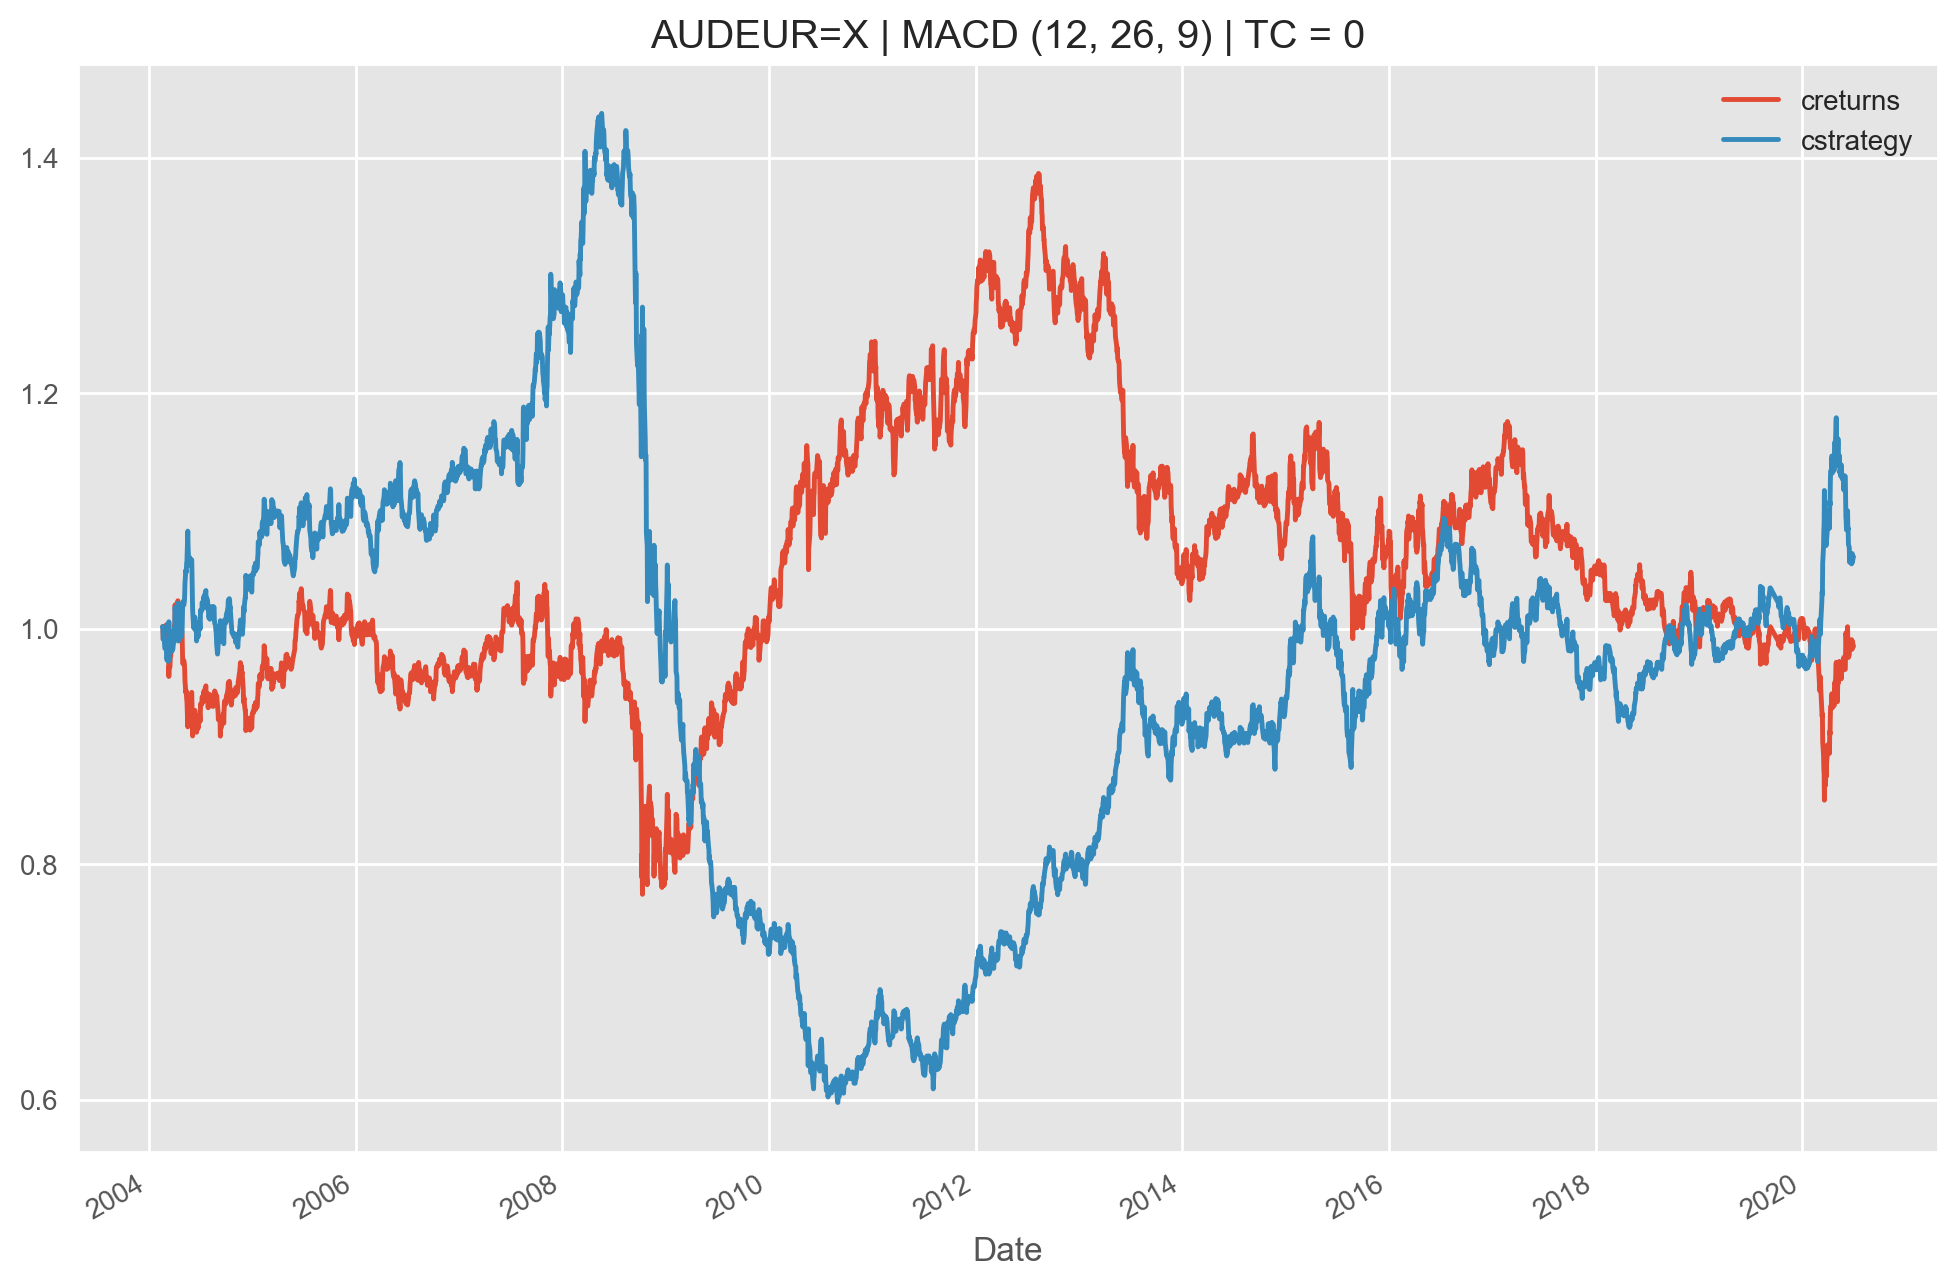

In [129]:
tester.plot_results()

In [130]:
tester.optimize_parameters((5, 20, 1), (21, 50, 1), (5, 20, 1))

(array([ 5., 23.,  6.]), 2.183987)

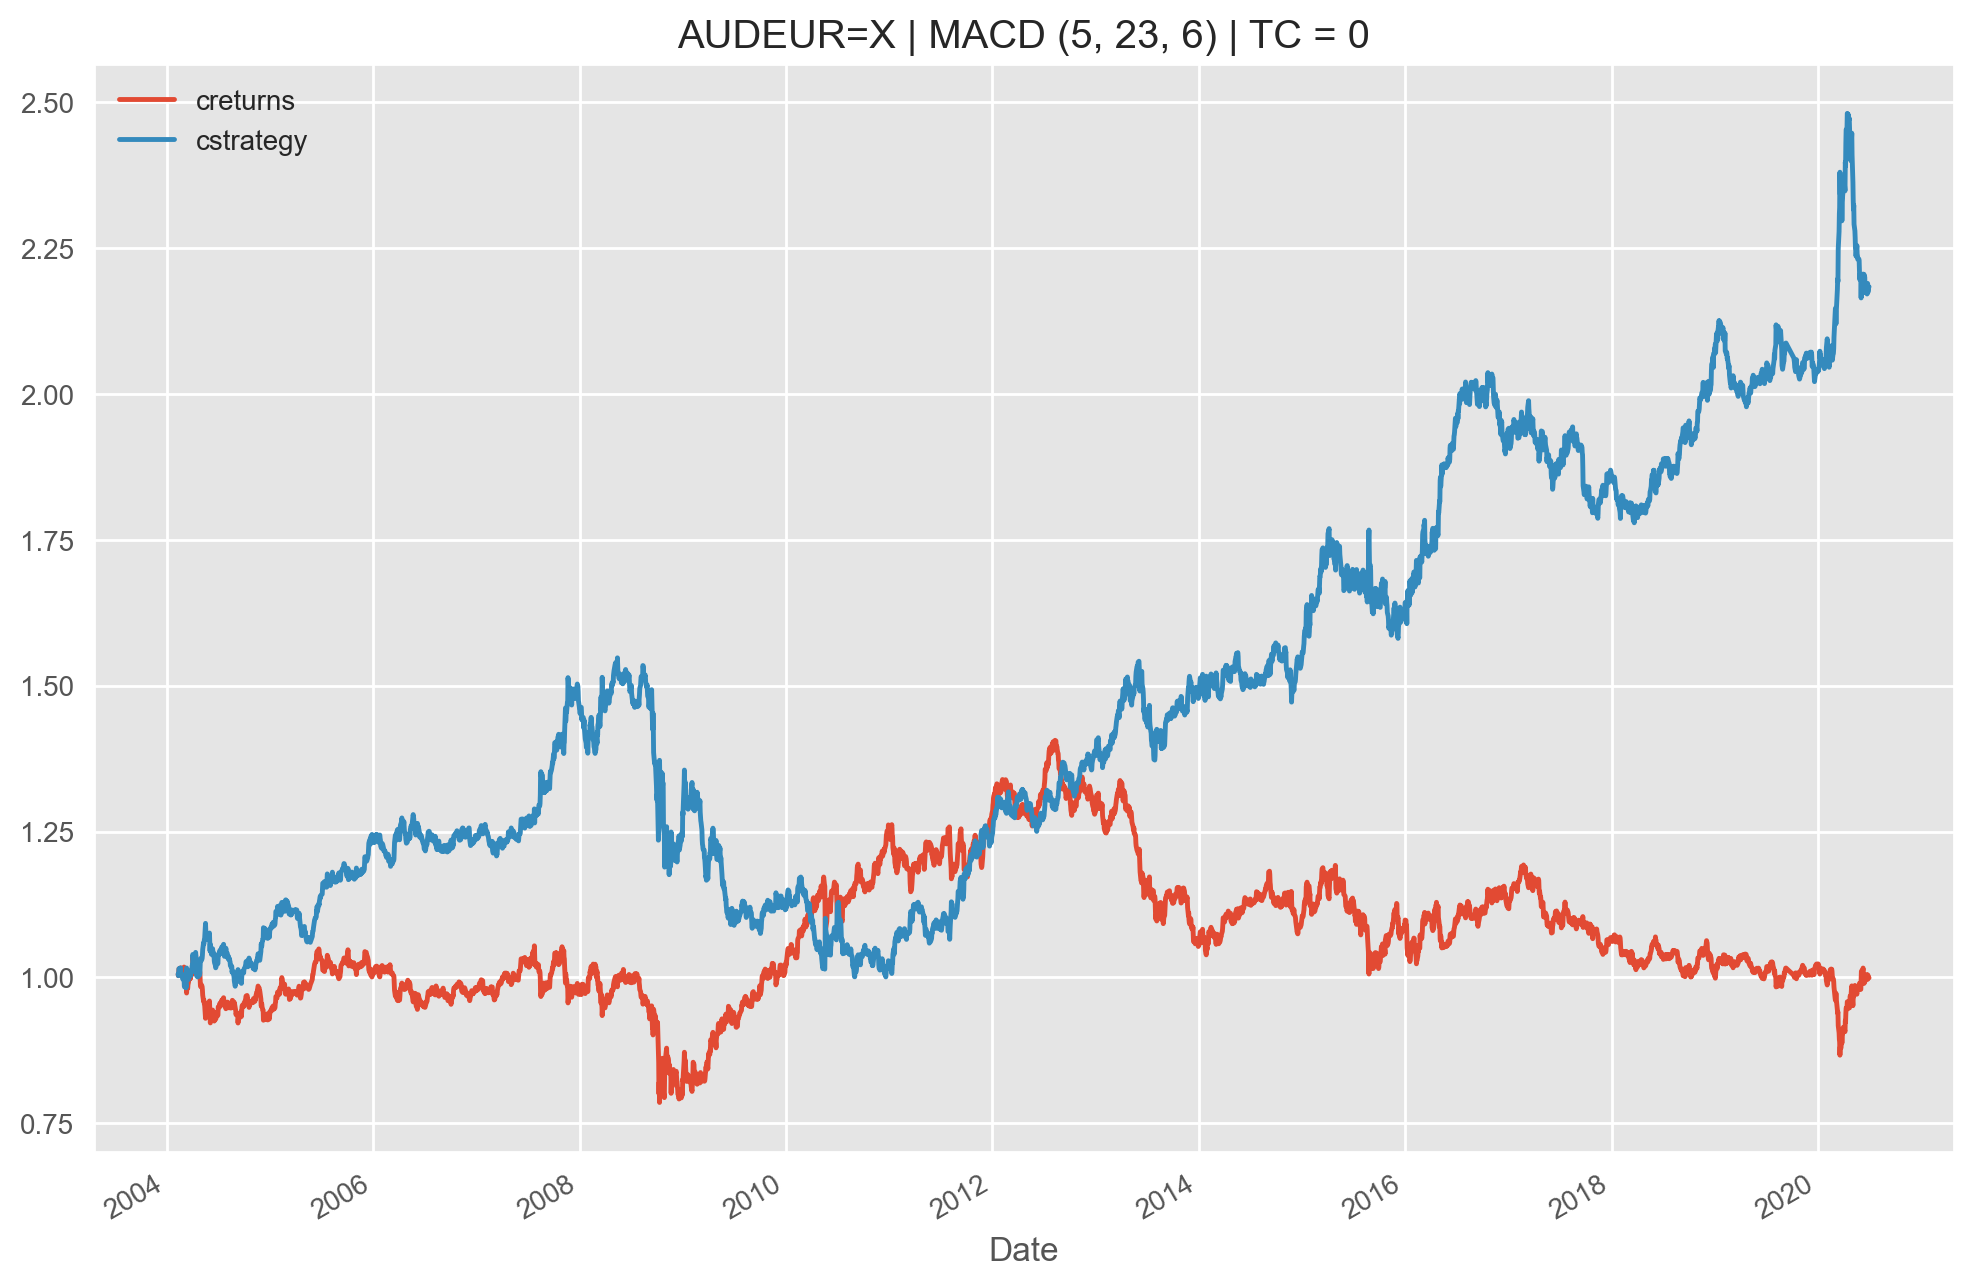

In [131]:
tester.plot_results()

__Optimization and Backtesting (2004-2014)__ ("In-Sample")

In [132]:
tester = MACD("AUDEUR=X", EMA_S = 12, EMA_L = 26, signal_mw = 9,
              start = "2004-01-01", end = "2014-12-31", tc = 0)

In [133]:
tester.optimize_parameters((5, 20, 1), (21, 50, 1), (5, 20, 1))

(array([ 6., 24.,  7.]), 1.56004)

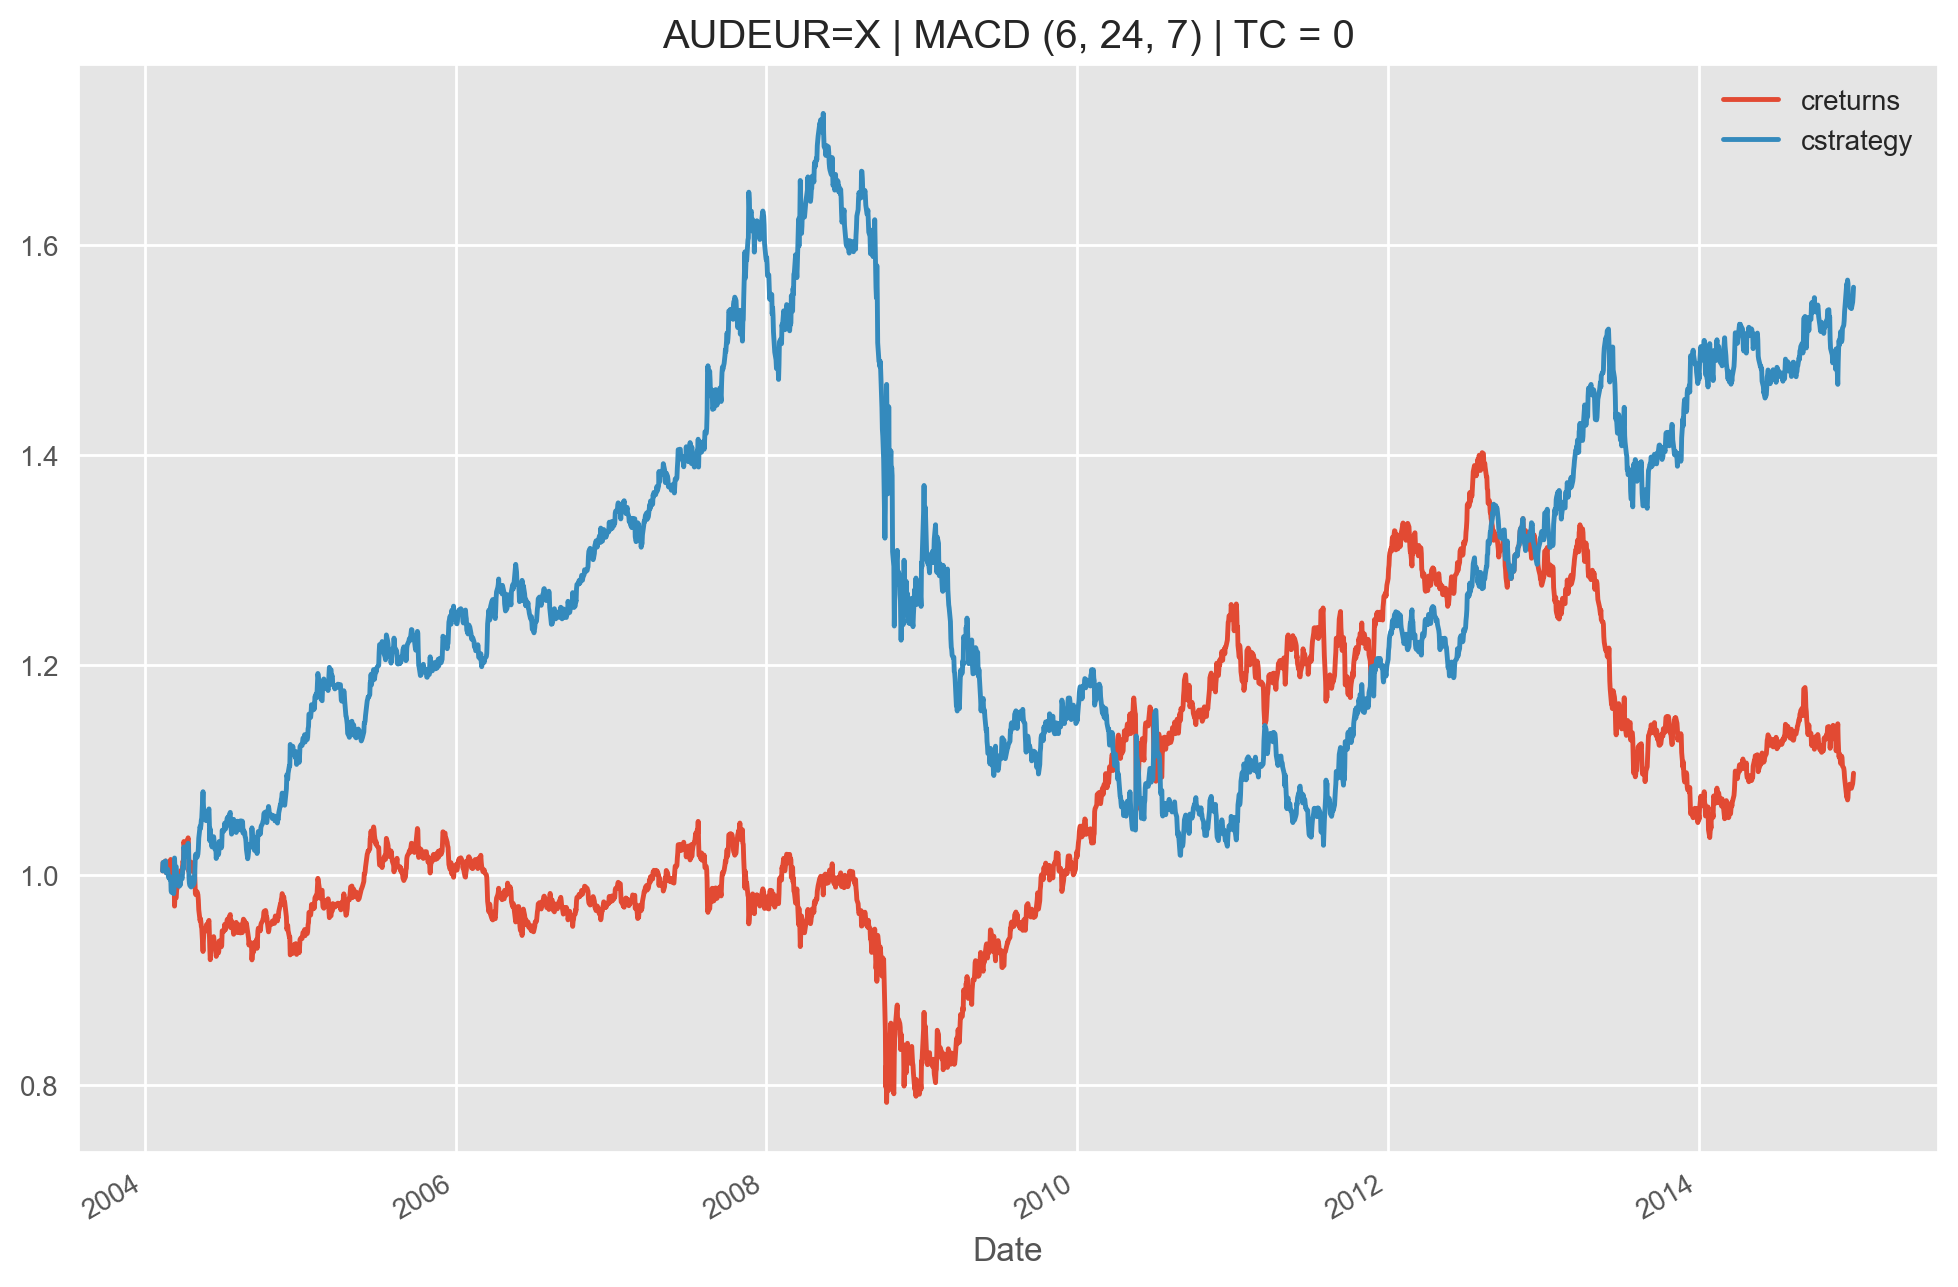

In [134]:
tester.plot_results()

__Forward Testing (2015-2020)__ ("Out-Sample")

In [135]:
forwardtester = MACD("AUDEUR=X", EMA_S = 6, EMA_L = 24, signal_mw = 7,
                     start = "2015-01-01", end = "2020-06-30", tc = 0)

In [136]:
forwardtester.test_strategy()

(1.237419, 0.348736)

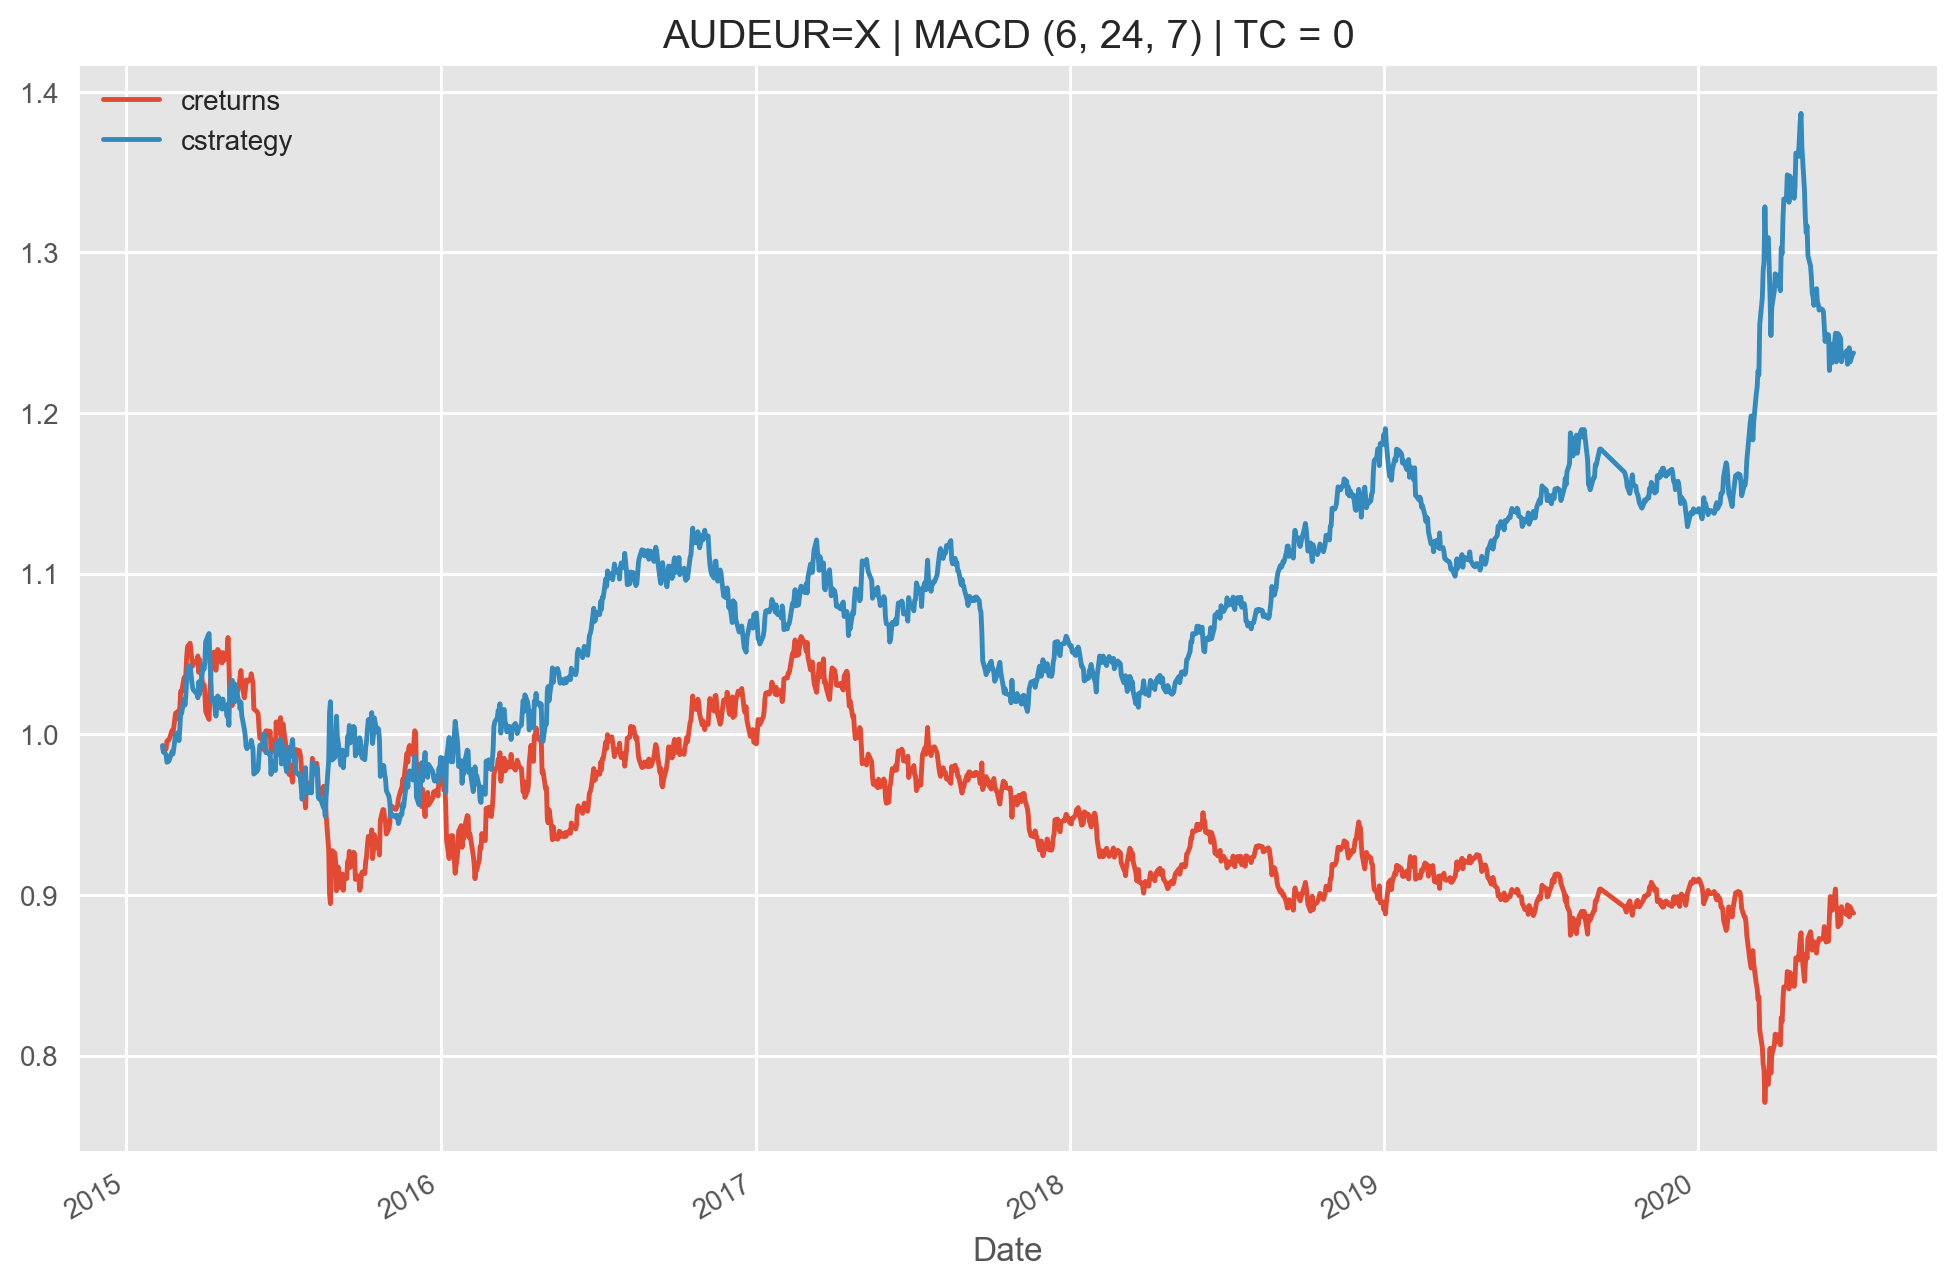

In [137]:
forwardtester.plot_results()

## Alternative Strategies and Interpretations

In [138]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brute
plt.style.use("seaborn-v0_8")
from MACDBacktester import MACDBacktester as MACD

In [139]:
tester = MACD("EURUSD=X", EMA_S = 12, EMA_L = 26, signal_mw = 9,
              start = "2004-01-01", end = "2020-06-30", tc = 0)

In [140]:
alt = tester.data.dropna()
alt

,price,returns,EMA_S,EMA_L,MACD,MACD_Signal
Date,,,,,,
2004-02-17,1.285793,0.007251,1.271256,1.266191,0.005065,0.003018
2004-02-18,1.272508,-0.010386,1.271449,1.266693,0.004756,0.003408
2004-02-19,1.275705,0.002510,1.272106,1.267405,0.004700,0.003691
2004-02-20,1.254202,-0.017000,1.269345,1.266367,0.002978,0.003538
2004-02-23,1.257197,0.002386,1.267473,1.265649,0.001824,0.003175
...,...,...,...,...,...,...
2020-06-24,1.131235,0.002892,1.125123,1.117852,0.007272,0.008516
2020-06-25,1.125087,-0.005449,1.125118,1.118388,0.006730,0.008158
2020-06-26,1.122208,-0.002562,1.124670,1.118671,0.005999,0.007727


__Main Strategy: MACD Signal Line Crossover__

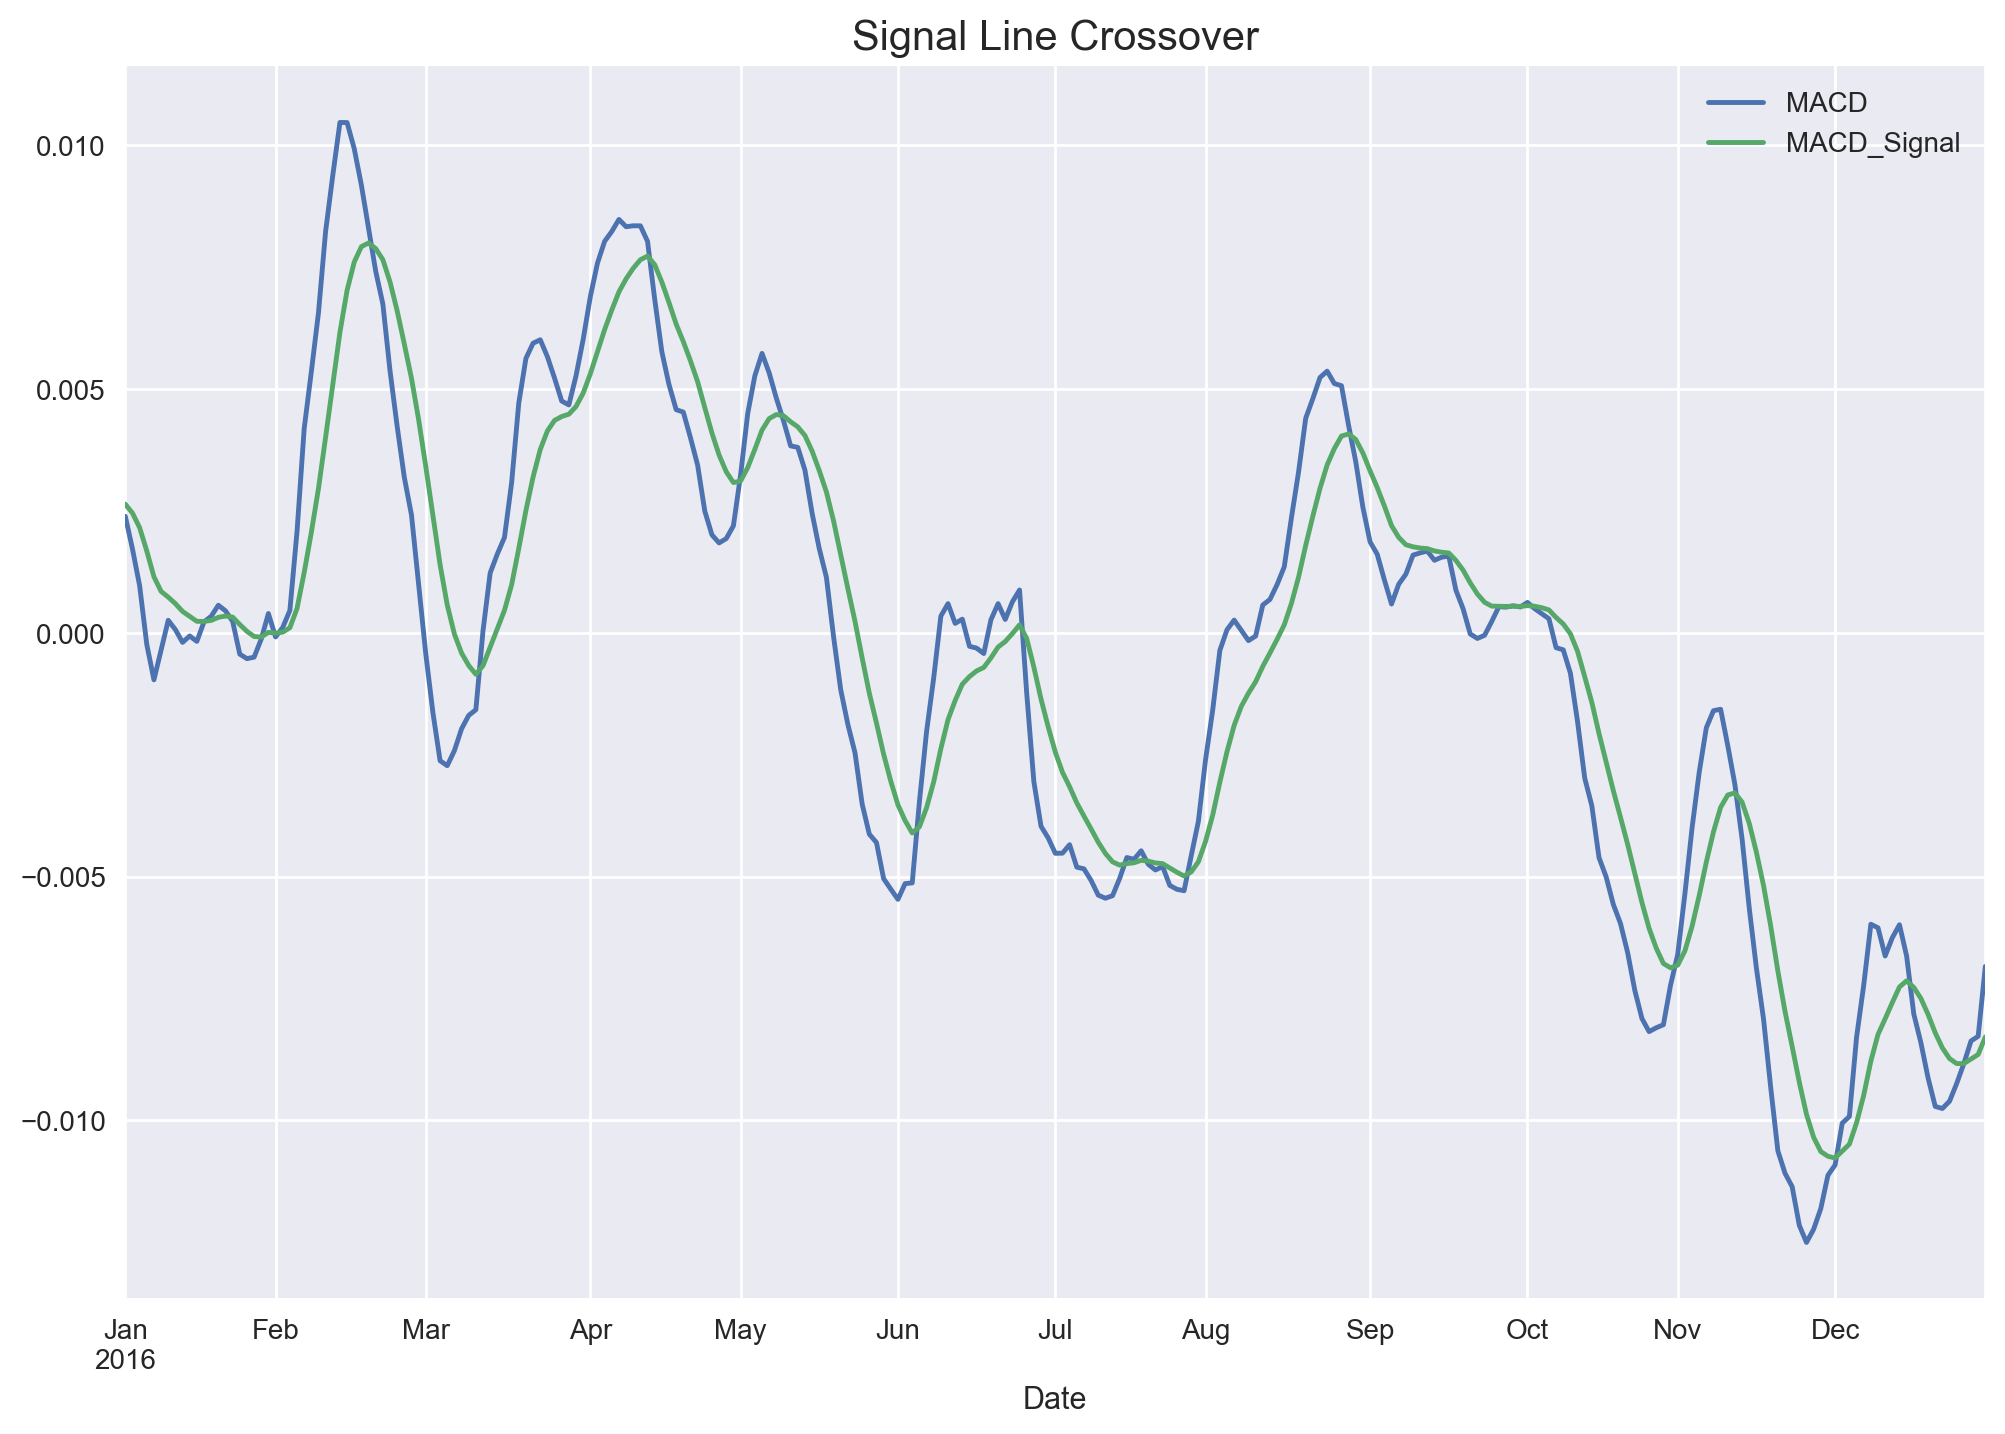

In [141]:
alt.loc["2016", ["MACD", "MACD_Signal"]].plot(figsize = (12, 8))
#plt.hlines(y = 0, xmin = alt.index[0], xmax = alt.index[-1], color = "r", label = "Zero")
plt.title("Signal Line Crossover", fontsize = 15)
plt.legend()
plt.show()

__Alternative 1: Zero Crossover__

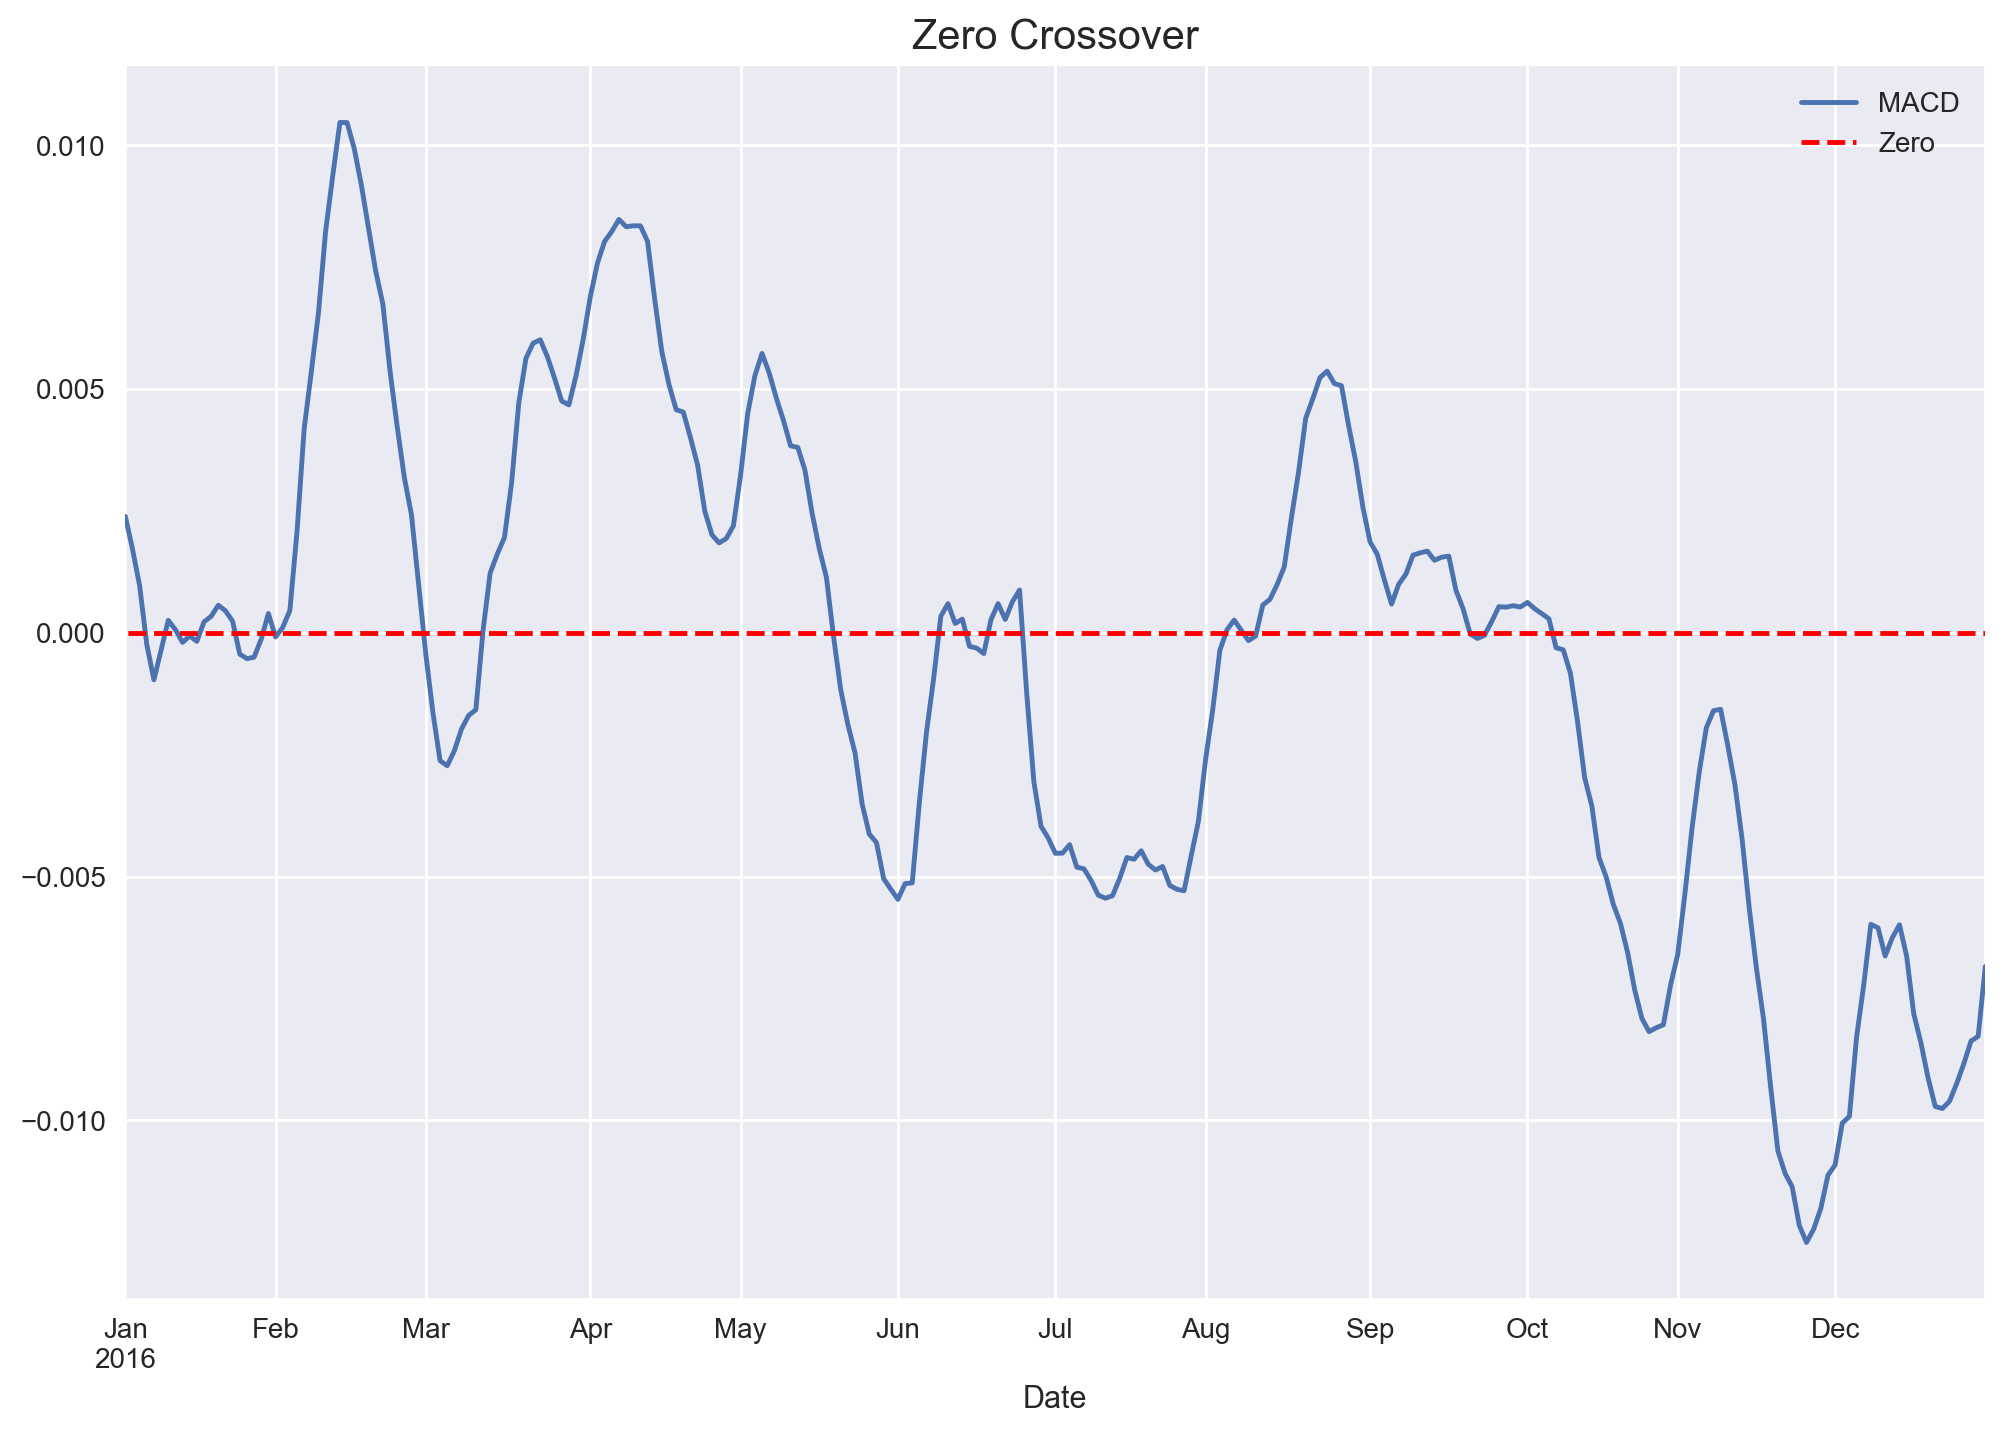

In [143]:
alt.loc["2016", "MACD"].plot(figsize = (12, 8))
plt.hlines(y = 0, xmin = alt.index[0], xmax = alt.index[-1], color = "r", label = "Zero" , ls = "--")
plt.title("Zero Crossover", fontsize = 15)
plt.legend()
plt.show()

__Alternative 2: Divergence__

Convergence: 
- if __Price__ reaches __higher highs__ -> __MACD__ reaches __higher highs__ (confirmation)
- if __Price__ reaches __lower lows__ -> __MACD__ reaches __lower lows__ (confirmation) 

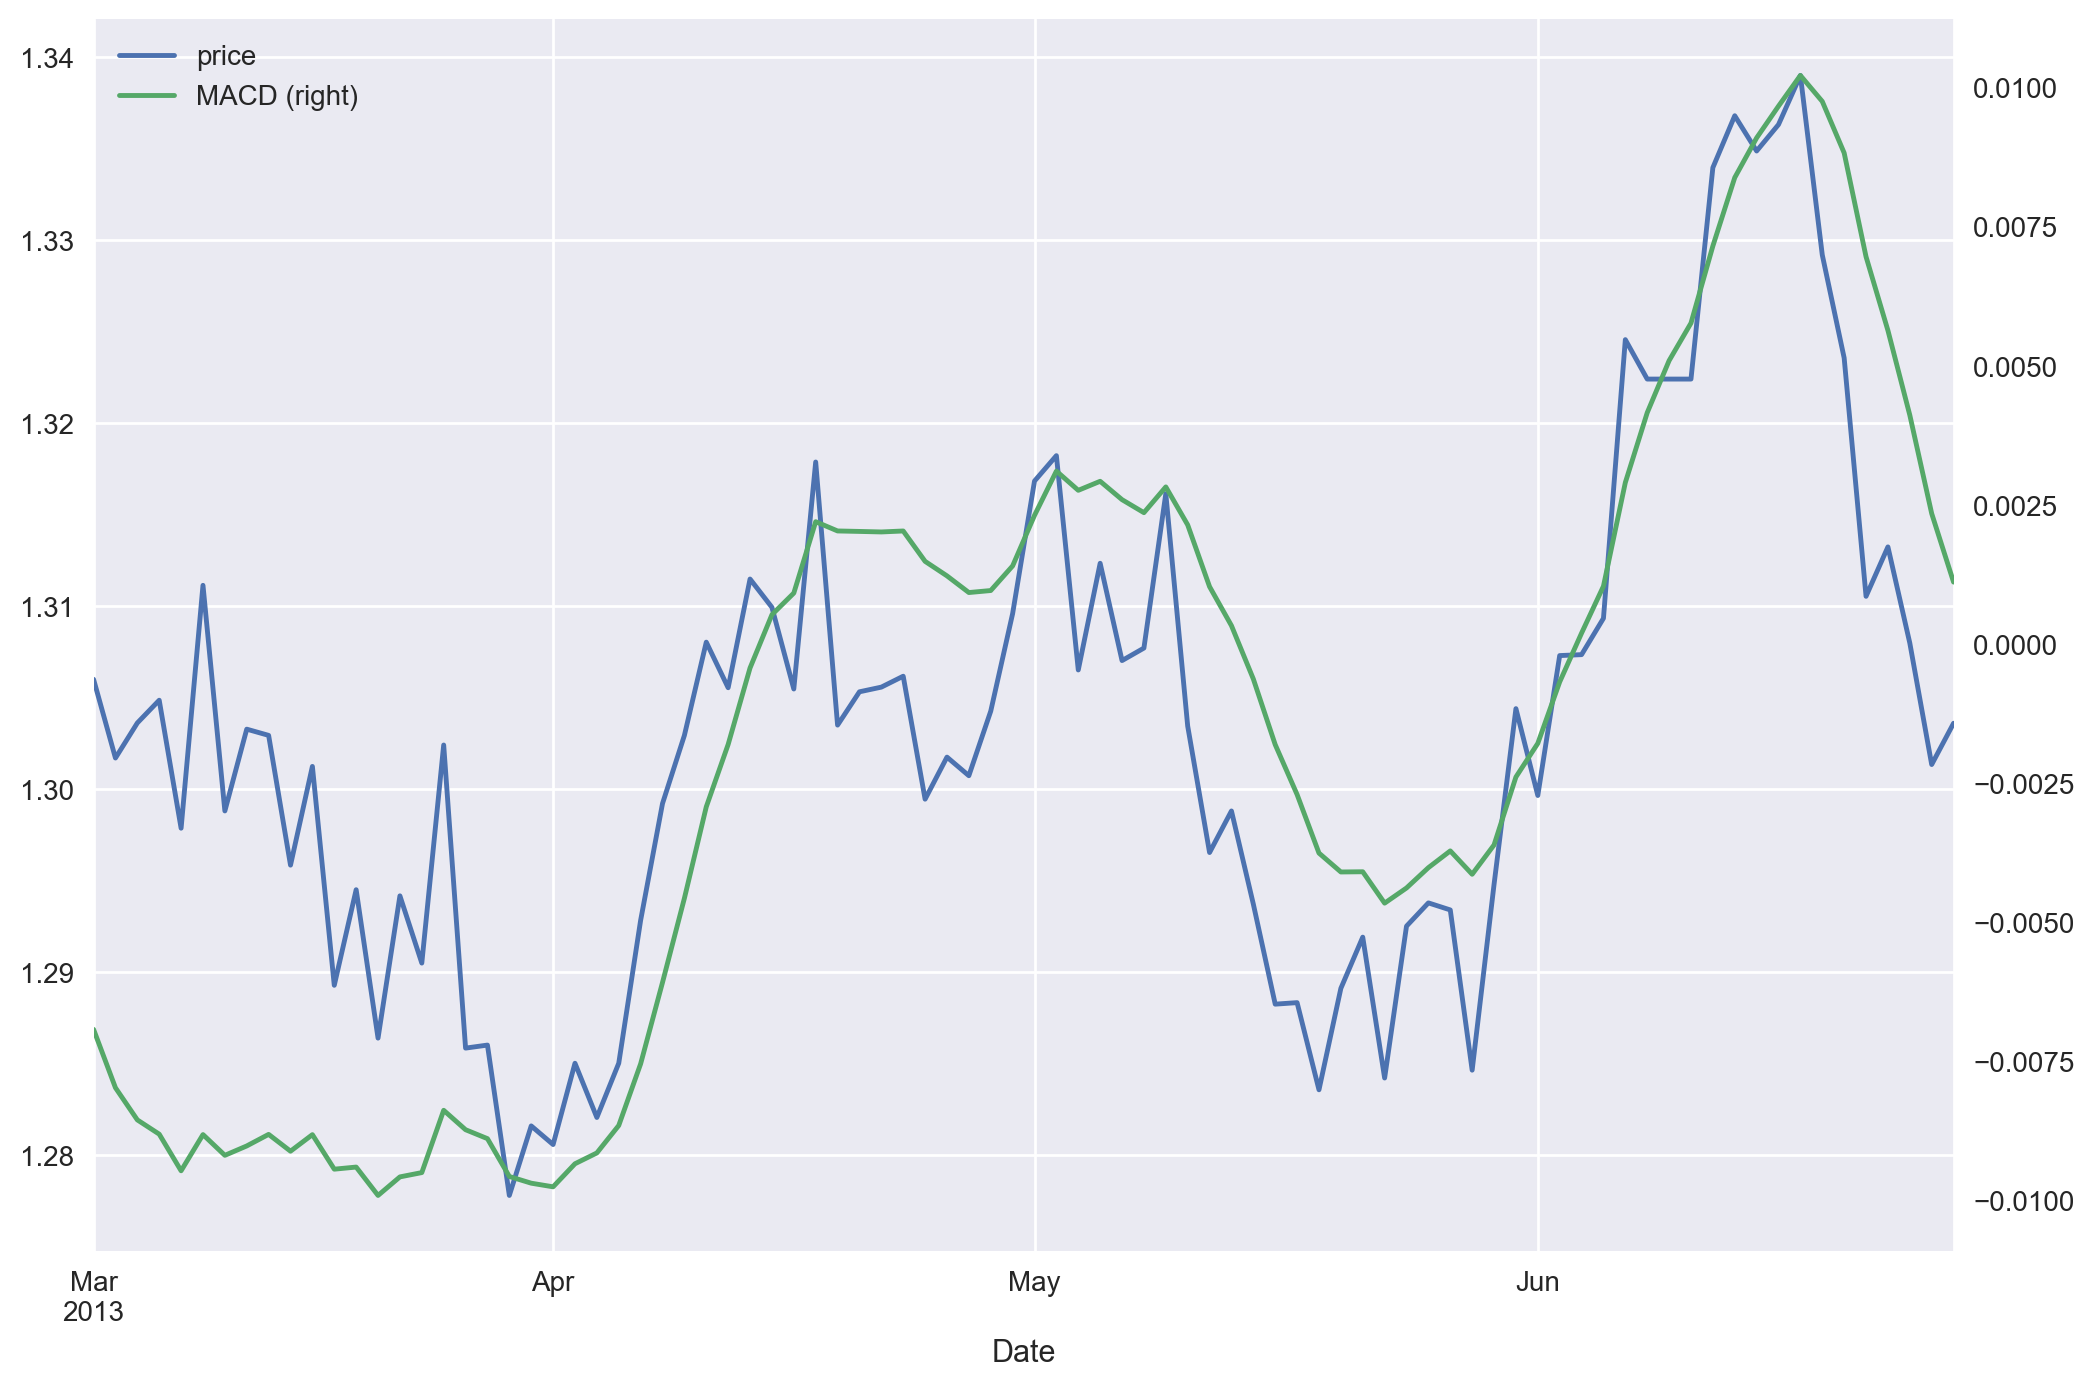

In [144]:
alt.loc["03-2013":"06-2013", ["price", "MACD"]].plot(figsize = (12, 8), secondary_y = "MACD")
plt.show()

Divergence: 
- if __Price__ reaches __higher highs__ -> __MACD fails__ to reach higher highs (__Bearish Divergence__)
- if __Price__ reaches __lower lows__ -> __MACD fails__ to reach lower lows (__Bullish Divergence__)

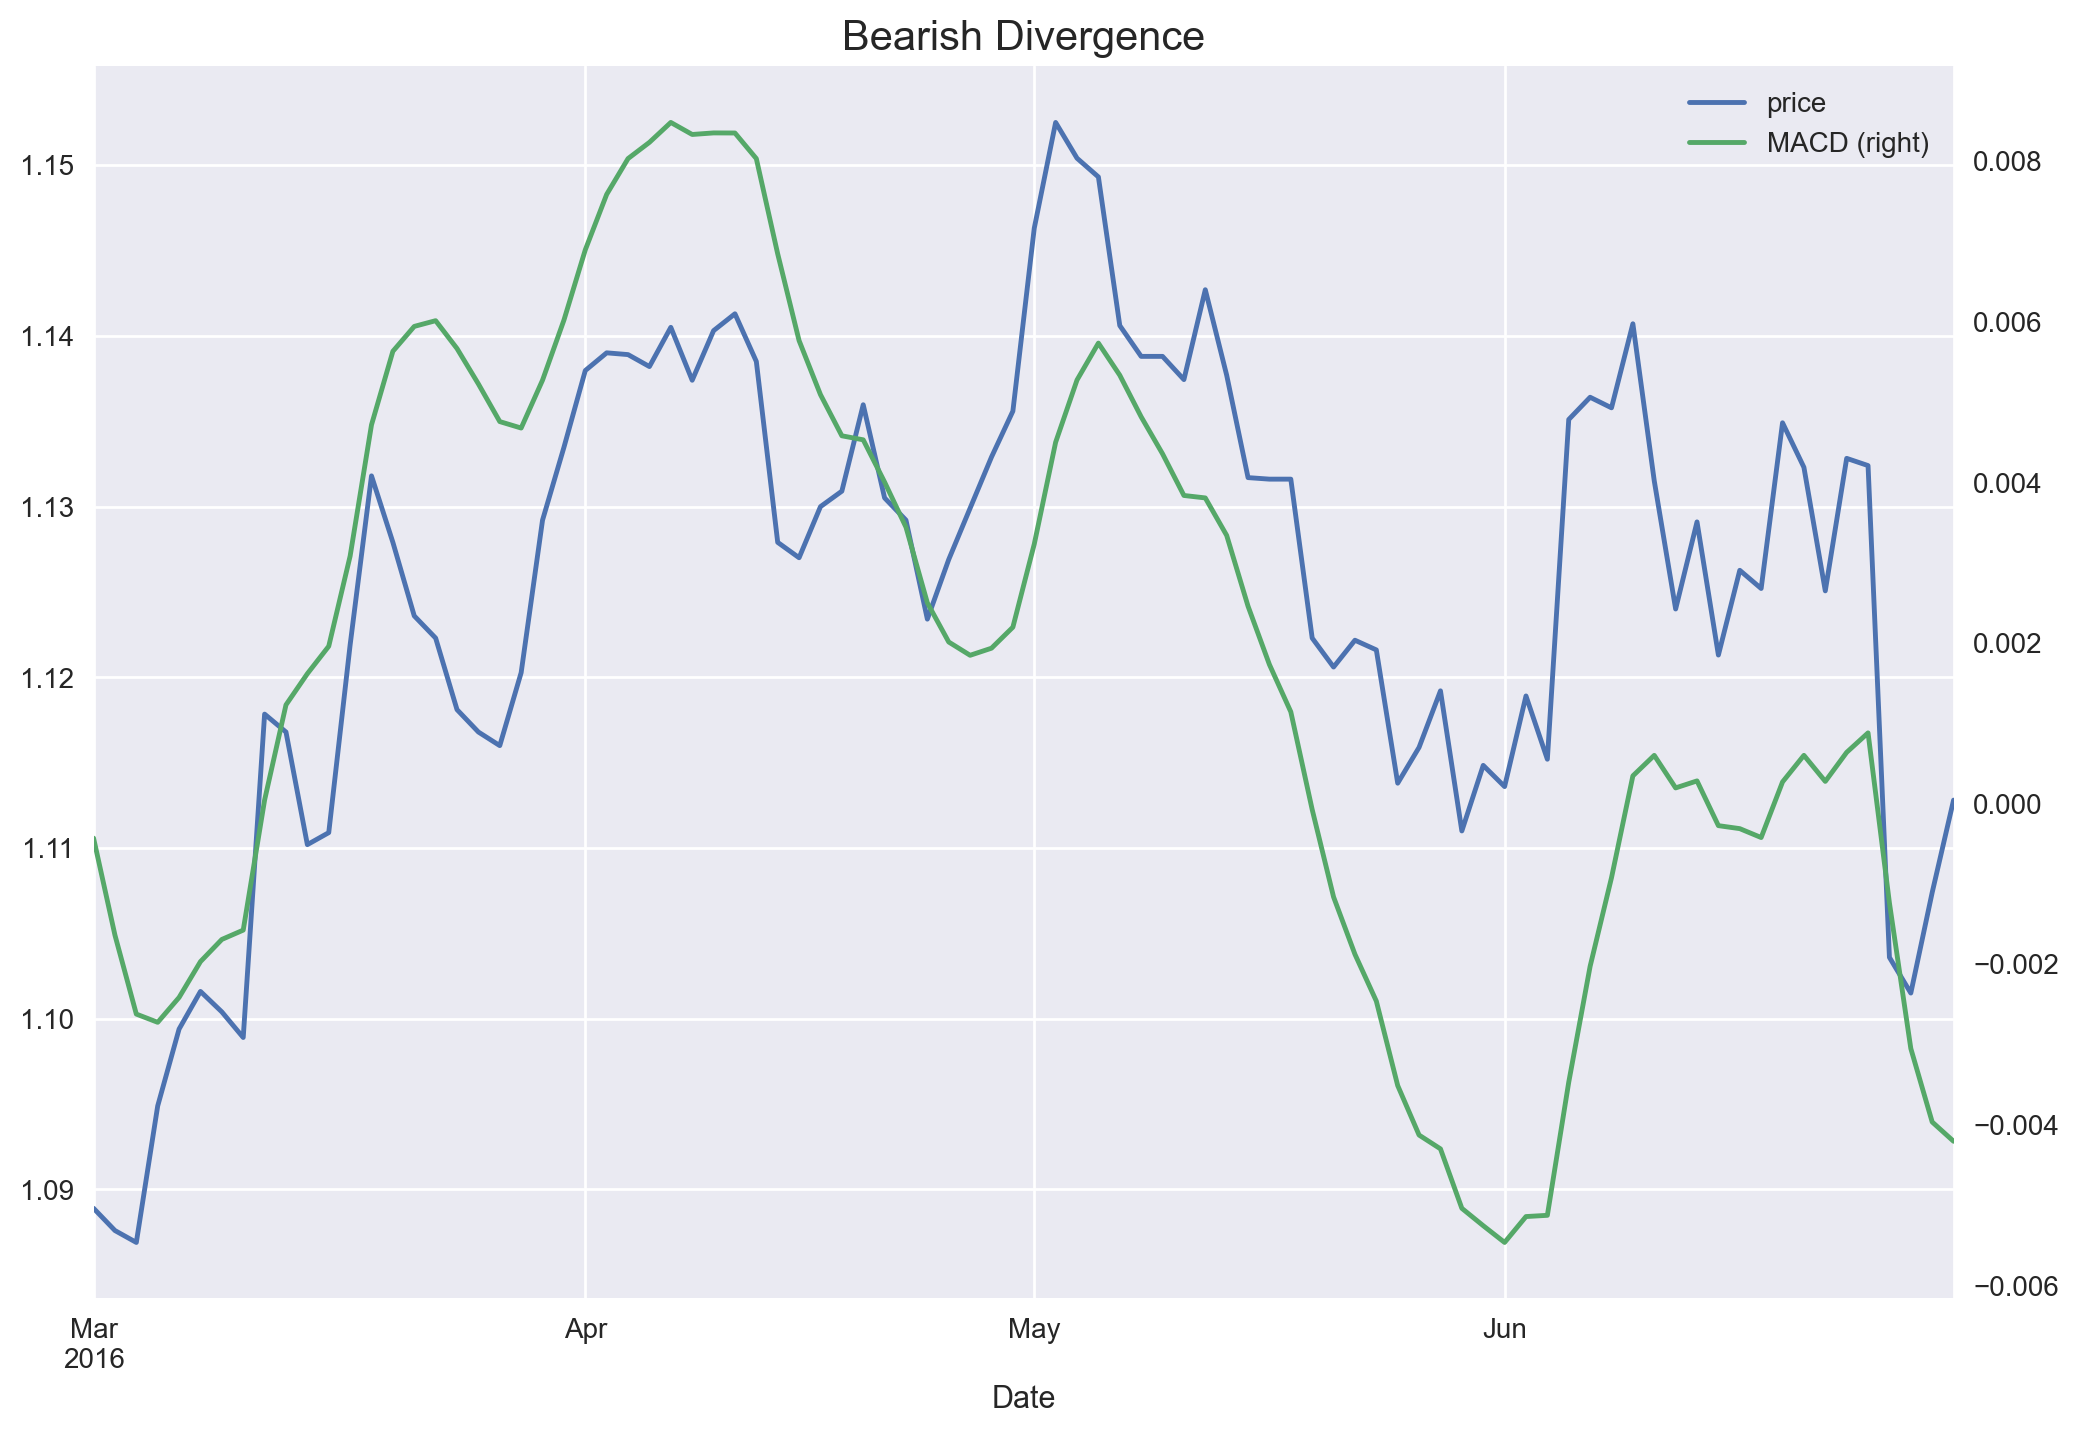

In [145]:
alt.loc["03-2016":"06-2016", ["price", "MACD"]].plot(figsize = (12, 8), secondary_y = "MACD")
plt.title("Bearish Divergence", fontsize = 15)
plt.show()

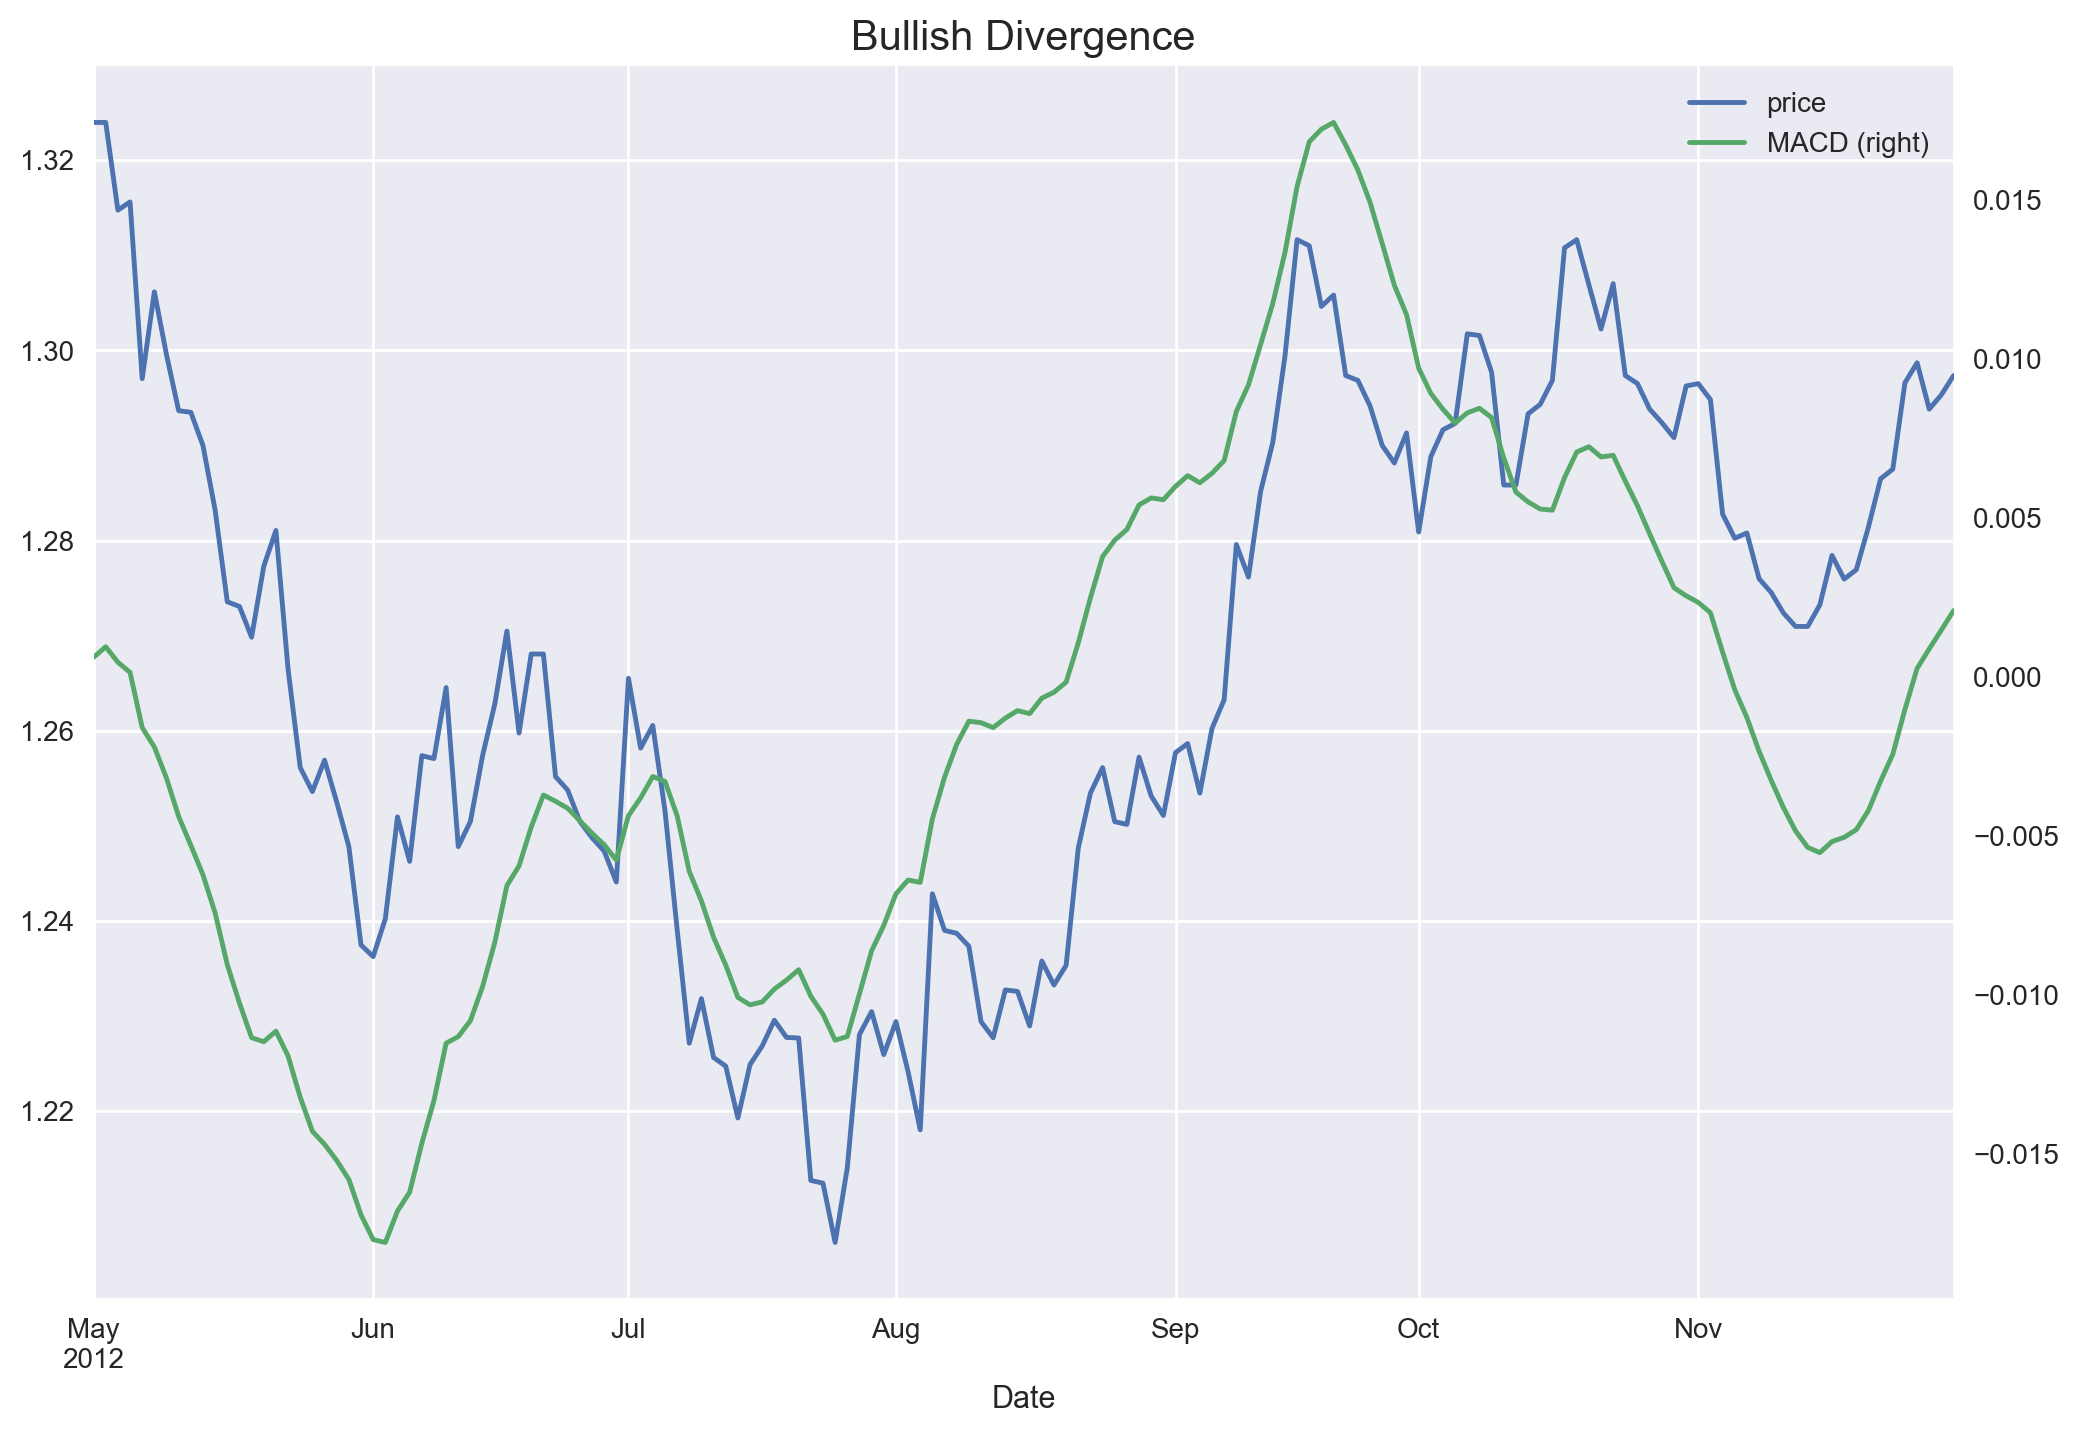

In [146]:
alt.loc["05-2012":"11-2012", ["price", "MACD"]].plot(figsize = (12, 8), secondary_y = "MACD")
plt.title("Bullish Divergence", fontsize = 15)
plt.show()